# Chunk-Based Analysis to Reduce Memory Usage, using XArray, HDF5, and Dask

Scientific datasets are increasingly too large to load into memory all at once. High-resolution imaging, large simulation outputs, and long experimental recordings can easily exceed the RAM available on a typical workstation. If analysis requires loading the entire dataset before computation begins, many otherwise simple operations become impossible.

This notebook introduces a different approach: chunk-based analysis. Instead of loading an entire dataset into memory, data can be processed in smaller pieces. Modern scientific Python tools — particularly XArray, NetCDF/HDF5, and Dask—make this possible while keeping the code readable and close to the mathematical operations scientists want to perform. The goal is to understand how these tools cooperate to reduce memory pressure and enable scalable analysis pipelines.

The notebook proceeds in stages. First, you will learn the basic structure of XArray objects, which add labeled dimensions and metadata to NumPy-style arrays. Next, you will see how these arrays can be saved to NetCDF/HDF5 files, enabling efficient on-disk storage with compression and encoding options. Finally, you will explore how lazy loading and chunked computation allow large analyses to run without loading the entire dataset into memory, and how Dask coordinates the computation behind the scenes.

## Setup

### Import Packages

In [1]:
import dask.distributed
import netCDF4
import numpy as np
import xarray as xr

ModuleNotFoundError: dask.distributed is not installed.

Please either conda or pip install distributed:

  conda install dask distributed             # either conda install
  python -m pip install "dask[distributed]" --upgrade    # or pip install

### Utility Functions

In [ ]:
from contextlib import contextmanager
import os
import sys

import matplotlib.pyplot as plt
from memory_profiler import memory_usage
import pandas as pd


def _generate_calcium_data_file(fname="calcium_imaging_session.nc", nx=256, ny=256, nt=4000, n_cells=12, baseline=0.15, noise_sd=0.05) -> None:
    import numpy as np
    import xarray as xr
    
    time = np.linspace(2, 20, nt)
    
    rng = np.random.default_rng(42)
    
    # coordinate grids
    x = np.arange(nx)
    y = np.arange(ny)
    X, Y = np.meshgrid(x, y, indexing="ij")
    
    # ----------------------------
    # Background signal
    # ----------------------------
    # Start with baseline + pixel noise
    data = baseline + rng.normal(0, noise_sd, size=(nx, ny, nt))
    
    # Add slow global drift over time
    slow_drift = (
        0.03 * np.sin(2 * np.pi * time / 9.0)
        + 0.02 * np.sin(2 * np.pi * time / 3.7 + 1.2)
    )
    data += slow_drift[None, None, :]
    
    # Add a weak spatial background gradient
    spatial_bg = 0.03 * ((X / nx) + (Y / ny))
    data += spatial_bg[:, :, None]
    
    # ----------------------------
    # Shared neuropil-like signal
    # ----------------------------
    shared_events = rng.poisson(0.003, size=nt).astype(float)
    
    kernel_len = 120
    tau = 18
    kernel = np.exp(-np.arange(kernel_len) / tau)
    shared_trace = np.convolve(shared_events, kernel, mode="full")[:nt]
    shared_trace /= shared_trace.max() + 1e-12
    shared_trace *= 0.05
    
    data += shared_trace[None, None, :]
    
    # Add synthetic cells
    cell_masks = []
    cell_traces = []
    
    for i in range(n_cells):
        # random cell center, avoiding borders
        cx = rng.integers(20, nx - 20)
        cy = rng.integers(20, ny - 20)
    
        # random elliptical Gaussian footprint
        sx = rng.uniform(3, 8)
        sy = rng.uniform(3, 8)
        amp = rng.uniform(0.2, 0.8)
    
        footprint = np.exp(-(((X - cx) ** 2) / (2 * sx**2) + ((Y - cy) ** 2) / (2 * sy**2)))
        footprint *= amp
    
        # sparse spike/event train
        event_rate = rng.uniform(0.002, 0.01)
        spikes = rng.poisson(event_rate, size=nt).astype(float)
    
        # calcium decay kernel
        tau_decay = rng.uniform(8, 30)
        kernel_len = 200
        decay_kernel = np.exp(-np.arange(kernel_len) / tau_decay)
    
        trace = np.convolve(spikes, decay_kernel, mode="full")[:nt]
    
        # normalize and scale
        if trace.max() > 0:
            trace = trace / trace.max()
        trace *= rng.uniform(0.3, 1.2)
    
        # add a tiny bit of within-cell temporal noise
        trace += rng.normal(0, 0.01, size=nt)
        trace = np.clip(trace, 0, None)
    
        # add cell contribution to movie
        data += footprint[:, :, None] * trace[None, None, :]
    
        cell_masks.append(footprint)
        cell_traces.append(trace)
    
    
    # Clamp to nonnegative values
    data = np.clip(data, 0, None)
    
    # Build xarray object
    movie = xr.DataArray(
        data,
        name="image",
        dims=["x", "y", "time"],
        coords={
            "x": x,
            "y": y,
            "time": time,
        },
        attrs={
            "description": "Synthetic calcium imaging session with noisy background, drift, shared activity, and localized active cells"
        },
    )
    movie.to_netcdf(fname)



def _format_duration(seconds: float, precision: int = 1) -> str:
    """
    Takes a time in seconds and returns a string (e.g. ) that is more human-readable.

    Looking to do this in a real project?  Some alternatives:
      - `humanize`: https://humanize.readthedocs.io/en/latest/
    """


    if seconds < 0:
        raise ValueError("Duration must be non-negative")

    units = [("s", 1), ("ms", 1e-3), ("µs", 1e-6)]

    for unit, scale in units:
        if seconds >= scale:
            value = seconds / scale
            return f"{value:.{precision}f} {unit}"
    else:
        return f"{seconds / 1e-9:.{precision}f} ns"



@contextmanager
def _trace_lines_of(fun):
    "a (very) basic line tracer.  Collects (timestamp, lineno) for each executed line inside a function."
    import time
    try:
        target_code = fun.__code__
    except AttributeError:
        yield []
        return
    target_frame = None
    records = []

    def tracer(frame, event, arg):
        nonlocal target_frame

        if event == "call" and frame.f_code is target_code:
            target_frame = frame
            return tracer

        elif frame is target_frame:
            if event == "line":
                records.append((frame.f_lineno, time.perf_counter()))
            elif event == "return":
                target_frame = None

            return tracer

    old_trace = sys.gettrace()
    sys.settrace(tracer)

    try:
        yield records
    finally:
        sys.settrace(old_trace)


def _sample_memory(fun, interval=.00005):
    
    # Collect memory traces and line number timings
    with _trace_lines_of(fun) as line_trace:
        memory_trace = memory_usage(fun, interval=interval, timestamps=True)

    # Make Comparable DataFrames out of the two datasets
    line_trace_df = pd.DataFrame(line_trace, columns=['Line', 'Time'])
    if len(line_trace_df) > 0:
        line_trace_df.Time -= line_trace_df.Time[0]
    
    memory_trace = memory_trace[1:]
    
    memory_trace_df = pd.DataFrame(memory_trace, columns=['Memory', 'Time'])
    memory_trace_df['Time'] -= memory_trace_df['Time'][0]
    memory_trace_df['Memory'] -= memory_trace_df['Memory'][0]

    return line_trace_df, memory_trace_df


def _plot_memory(data: pd.DataFrame, x='Time', y='Memory', ax=None):
    "Makes a line plot."

    peak_memory_mb = round(data[y].max(), 1)
    total_time = _format_duration(data[x].max())

    ax = ax if ax is not None else plt.gca()
    ax.plot(data[x], data[y])
    ax.fill_between(data[x], data[y], 0, alpha=0.3)
    ax.set(xlabel='Time (s)', ylabel='Memory (MB)', title=f"Total Time: {total_time} -- Peak Memory: {peak_memory_mb} MB")

    ax.margins(y=0)
    
    ylim_max = data[y].max() * 1.05 if data[y].max() > 1 else 1
    ax.set_ylim(0, ylim_max)
    
    
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    return ax


def _plot_line_numbers(data: pd.DataFrame, x='Time', text='Line', linestyle='--', color='gray', alpha=0.3, fontsize=6, ax=None):
    "Makes vertical lines with text above them."
    
    ax = ax if ax is not None else plt.gca()
    ymin, ymax = ax.get_ylim()
    y_text = ymax - 0.04 * (ymax - ymin)

    for _, row in data.iterrows():
        ax.axvline(row[x], linestyle=linestyle, alpha=alpha, color=color)
        ax.text(row[x], y_text, str(int(row[text])), rotation=90, ha="right", va="bottom", fontsize=fontsize)
        
    return ax

def _analyze_memory(*funs, interval=.00005, linestyle='--', color='gray', alpha=0.3, fontsize=6):
    "Convenient wrapper function: records memory traces of provided functions and makes the plot"

    if len(funs) == 1:
        fig, axes = plt.subplots();
        axes = [axes]
    else:
        fig, axes = plt.subplots(nrows=len(funs), sharex=True)


    print(axes)
    for ax, fun in zip(axes, funs):
        lines, memory = _sample_memory(fun, interval=interval)
        # ax = ax if ax is not None else plt.gca()
        _plot_memory(memory, ax=ax)
        _plot_line_numbers(lines, linestyle=linestyle, color=color, alpha=alpha, fontsize=fontsize, ax=ax)
    
    y_max = max([ax.get_ylim()[1] for ax in axes])
    for ax in axes:
        ax.set_ylim(0, y_max)

    plt.tight_layout()


def _format_bytes(bytes: float, precision: int = 2) -> str:
    """
    Takes a time in seconds and returns a string (e.g. ) that is more human-readable.

    Looking to do this in a real project?  Some alternatives:
      - `humanfriendly`: https://pypi.org/project/humanfriendly/#getting-started
    """

    if bytes < 0:
        raise ValueError("bytes must be non-negative")

    units = [("KB", 1000), ("MB", 1_000_000), ("GB", 1_000_000_000), ("TB", 1_000_000_000_000)]

    for unit, scale in reversed(units):
        if bytes >= scale:
            value = bytes / scale
            return f"{value:.{precision}f} {unit}"
    else:
        return f"{bytes} B"

def _file_size(path: str) -> int:
    return os.path.getsize(path)

def _print_file_size(path: str, label='') -> None:
    text = _format_bytes(_file_size(path))
    if label:
        text = label + ': ' + text
    print(text)


class utils:
    analyze_memory = _analyze_memory
    generate_calcium_data_file = _generate_calcium_data_file
    print_file_size = _print_file_size

## Intro to Working with XArray

NumPy arrays are powerful but minimal: they store numerical data without any built-in information about what the axes represent. In scientific datasets, however, each axis usually corresponds to meaningful quantities such as space, time, wavelength, or experimental condition. When working with multidimensional data, it is often useful to label these dimensions explicitly.

**[XArray](https://docs.xarray.dev/en/stable/user-guide/index.html)** extends NumPy by adding labels and metadata to multidimensional arrays. Each array can have named dimensions, coordinate values, and descriptive metadata attached to it. This makes many operations clearer and safer, since calculations can reference dimensions by name rather than by numeric index. In addition, XArray integrates naturally with file formats such as NetCDF and with distributed computing tools like Dask.



### Exercises

The exercises in this section introduce the core concepts of XArray: treating a DataArray like a NumPy array, labeling dimensions, attaching coordinates, and adding metadata to describe the data.

#### `xr.DataArray()` as a Numpy-Like Array

At its core, an XArray DataArray wraps a NumPy array. Most numerical operations that work on NumPy arrays also work on DataArray objects, including slicing, aggregation, and arithmetic. This means that existing NumPy-style code often requires very little modification to work with labeled arrays.

**Example**: Create a three-dimensional `DataArray` from a Numpy array:

In [ ]:
da = xr.DataArray(
    data=np.random.random(size=(10, 20, 30))
)
da

<xarray.DataArray (dim_0: 10, dim_1: 20, dim_2: 30)> Size: 48kB
array([[[0.56084438, 0.05985552, 0.26420092, ..., 0.47128841,
 0.41480903, 0.58138428],
 [0.10852725, 0.3864639 , 0.43173687, ..., 0.06105856,
 0.42962668, 0.96545604],
 [0.55789829, 0.71002513, 0.86549567, ..., 0.19064758,
 0.38559176, 0.7831198 ],
 ...,
 [0.70052379, 0.57890067, 0.34900526, ..., 0.70995017,
 0.23136923, 0.53021091],
 [0.56980597, 0.55641717, 0.01313387, ..., 0.15875005,
 0.05196749, 0.81483301],
 [0.78855834, 0.75700278, 0.32341743, ..., 0.85621577,
 0.64020152, 0.96502773]],

 [[0.39161118, 0.40763263, 0.38432793, ..., 0.96064913,
 0.84116874, 0.2210865 ],
 [0.43896822, 0.76079706, 0.0778807 , ..., 0.81819822,
 0.74972017, 0.98523989],
 [0.17423573, 0.80608985, 0.46376746, ..., 0.21404438,
 0.26002065, 0.32884099],
...
 [0.11100777, 0.66356769, 0.30621201, ..., 0.23289448,
 0.26559422, 0.28562851],
 [0.23761443, 0.64714233, 0.59982479, ..., 0.30881483,
 0.39802479, 0.6689666 ],
 [0.70269768, 0.73881201, 0.15183471, ..., 0.49848133,
 0.3549302 , 0.12268393]],

 [[0.3309394 , 0.69463847, 0.90933485, ..., 0.07679523,
 0.41334066, 0.49865615],
 [0.35140187, 0.7911275 , 0.4577775 , ..., 0.45408909,
 0.72829416, 0.57879559],
 [0.87057944, 0.01596182, 0.42019643, ..., 0.14876181,
 0.7054708 , 0.80519276],
 ...,
 [0.21715799, 0.12867375, 0.48562055, ..., 0.44761488,
 0.59232888, 0.52619372],
 [0.56396101, 0.2859698 , 0.68644291, ..., 0.81620258,
 0.20501109, 0.68987415],
 [0.83213755, 0.01978695, 0.31419588, ..., 0.27207173,
 0.98482907, 0.69002495]]], shape=(10, 20, 30))
Dimensions without coordinates: dim_0, dim_1, dim_2 xarray.DataArray dim_0 : 10 dim_1 : 20 dim_2 : 30 0.5608 0.05986 0.2642 0.4934 0.9426 ... 0.1357 0.2721 0.9848 0.69 array([[[0.56084438, 0.05985552, 0.26420092, ..., 0.47128841,
 0.41480903, 0.58138428],
 [0.10852725, 0.3864639 , 0.43173687, ..., 0.06105856,
 0.42962668, 0.96545604],
 [0.55789829, 0.71002513, 0.86549567, ..., 0.19064758,
 0.38559176, 0.7831198 ],
 ...,
 [0.70052379, 0.57890067, 0.34900526, ..., 0.70995017,
 0.23136923, 0.53021091],
 [0.56980597, 0.55641717, 0.01313387, ..., 0.15875005,
 0.05196749, 0.81483301],
 [0.78855834, 0.75700278, 0.32341743, ..., 0.85621577,
 0.64020152, 0.96502773]],

 [[0.39161118, 0.40763263, 0.38432793, ..., 0.96064913,
 0.84116874, 0.2210865 ],
 [0.43896822, 0.76079706, 0.0778807 , ..., 0.81819822,
 0.74972017, 0.98523989],
 [0.17423573, 0.80608985, 0.46376746, ..., 0.21404438,
 0.26002065, 0.32884099],
...
 [0.11100777, 0.66356769, 0.30621201, ..., 0.23289448,
 0.26559422, 0.28562851],
 [0.23761443, 0.64714233, 0.59982479, ..., 0.30881483,
 0.39802479, 0.6689666 ],
 [0.70269768, 0.73881201, 0.15183471, ..., 0.49848133,
 0.3549302 , 0.12268393]],

 [[0.3309394 , 0.69463847, 0.90933485, ..., 0.07679523,
 0.41334066, 0.49865615],
 [0.35140187, 0.7911275 , 0.4577775 , ..., 0.45408909,
 0.72829416, 0.57879559],
 [0.87057944, 0.01596182, 0.42019643, ..., 0.14876181,
 0.7054708 , 0.80519276],
 ...,
 [0.21715799, 0.12867375, 0.48562055, ..., 0.44761488,
 0.59232888, 0.52619372],
 [0.56396101, 0.2859698 , 0.68644291, ..., 0.81620258,
 0.20501109, 0.68987415],
 [0.83213755, 0.01978695, 0.31419588, ..., 0.27207173,
 0.98482907, 0.69002495]]], shape=(10, 20, 30))

**Exercise**: Select the first 5 rows of `da`, using the slicing synatax `x[:10, :, :]`

In [ ]:
da[:5, :, :]

<xarray.DataArray (dim_0: 5, dim_1: 20, dim_2: 30)> Size: 24kB
array([[[0.56084438, 0.05985552, 0.26420092, ..., 0.47128841,
 0.41480903, 0.58138428],
 [0.10852725, 0.3864639 , 0.43173687, ..., 0.06105856,
 0.42962668, 0.96545604],
 [0.55789829, 0.71002513, 0.86549567, ..., 0.19064758,
 0.38559176, 0.7831198 ],
 ...,
 [0.70052379, 0.57890067, 0.34900526, ..., 0.70995017,
 0.23136923, 0.53021091],
 [0.56980597, 0.55641717, 0.01313387, ..., 0.15875005,
 0.05196749, 0.81483301],
 [0.78855834, 0.75700278, 0.32341743, ..., 0.85621577,
 0.64020152, 0.96502773]],

 [[0.39161118, 0.40763263, 0.38432793, ..., 0.96064913,
 0.84116874, 0.2210865 ],
 [0.43896822, 0.76079706, 0.0778807 , ..., 0.81819822,
 0.74972017, 0.98523989],
 [0.17423573, 0.80608985, 0.46376746, ..., 0.21404438,
 0.26002065, 0.32884099],
...
 [0.90850966, 0.87059301, 0.19071241, ..., 0.4255207 ,
 0.96381387, 0.81760381],
 [0.92418469, 0.89778235, 0.99194326, ..., 0.48321241,
 0.16014353, 0.94756438],
 [0.49328976, 0.30829586, 0.11021287, ..., 0.07204183,
 0.30528661, 0.68208352]],

 [[0.61062606, 0.80460679, 0.22634984, ..., 0.30736384,
 0.60836086, 0.64350759],
 [0.45331881, 0.36370919, 0.78931593, ..., 0.87367413,
 0.20003788, 0.59738912],
 [0.08122632, 0.79414561, 0.31617935, ..., 0.58099108,
 0.32038363, 0.17779246],
 ...,
 [0.45341472, 0.75321428, 0.12060224, ..., 0.7743897 ,
 0.62092623, 0.80009288],
 [0.6406274 , 0.17071222, 0.71592067, ..., 0.16887786,
 0.99672684, 0.35300175],
 [0.2557171 , 0.99460682, 0.15860442, ..., 0.97421229,
 0.54054542, 0.45186556]]], shape=(5, 20, 30))
Dimensions without coordinates: dim_0, dim_1, dim_2 xarray.DataArray dim_0 : 5 dim_1 : 20 dim_2 : 30 0.5608 0.05986 0.2642 0.4934 0.9426 ... 0.9443 0.9742 0.5405 0.4519 array([[[0.56084438, 0.05985552, 0.26420092, ..., 0.47128841,
 0.41480903, 0.58138428],
 [0.10852725, 0.3864639 , 0.43173687, ..., 0.06105856,
 0.42962668, 0.96545604],
 [0.55789829, 0.71002513, 0.86549567, ..., 0.19064758,
 0.38559176, 0.7831198 ],
 ...,
 [0.70052379, 0.57890067, 0.34900526, ..., 0.70995017,
 0.23136923, 0.53021091],
 [0.56980597, 0.55641717, 0.01313387, ..., 0.15875005,
 0.05196749, 0.81483301],
 [0.78855834, 0.75700278, 0.32341743, ..., 0.85621577,
 0.64020152, 0.96502773]],

 [[0.39161118, 0.40763263, 0.38432793, ..., 0.96064913,
 0.84116874, 0.2210865 ],
 [0.43896822, 0.76079706, 0.0778807 , ..., 0.81819822,
 0.74972017, 0.98523989],
 [0.17423573, 0.80608985, 0.46376746, ..., 0.21404438,
 0.26002065, 0.32884099],
...
 [0.90850966, 0.87059301, 0.19071241, ..., 0.4255207 ,
 0.96381387, 0.81760381],
 [0.92418469, 0.89778235, 0.99194326, ..., 0.48321241,
 0.16014353, 0.94756438],
 [0.49328976, 0.30829586, 0.11021287, ..., 0.07204183,
 0.30528661, 0.68208352]],

 [[0.61062606, 0.80460679, 0.22634984, ..., 0.30736384,
 0.60836086, 0.64350759],
 [0.45331881, 0.36370919, 0.78931593, ..., 0.87367413,
 0.20003788, 0.59738912],
 [0.08122632, 0.79414561, 0.31617935, ..., 0.58099108,
 0.32038363, 0.17779246],
 ...,
 [0.45341472, 0.75321428, 0.12060224, ..., 0.7743897 ,
 0.62092623, 0.80009288],
 [0.6406274 , 0.17071222, 0.71592067, ..., 0.16887786,
 0.99672684, 0.35300175],
 [0.2557171 , 0.99460682, 0.15860442, ..., 0.97421229,
 0.54054542, 0.45186556]]], shape=(5, 20, 30))

**Exercise**: Compute the mean, using either `DataArray.mean()` or `np.mean()`

In [ ]:
da.mean()

<xarray.DataArray ()> Size: 8B
array(0.49752817) xarray.DataArray 0.4975 array(0.49752817)

In [ ]:
np.mean(da)

<xarray.DataArray ()> Size: 8B
array(0.49752817) xarray.DataArray 0.4975 array(0.49752817)

**Exercise**: Compute the mean over the third axis, using `da.mean(axis=2)`

In [ ]:
da.mean(axis=2)

<xarray.DataArray (dim_0: 10, dim_1: 20)> Size: 2kB
array([[0.49848418, 0.44841185, 0.46261644, 0.47215094, 0.52182931,
 0.42590408, 0.40622036, 0.4410621 , 0.5366383 , 0.46220709,
 0.45112393, 0.51213825, 0.43388342, 0.54909941, 0.45991057,
 0.4471438 , 0.51065378, 0.49978541, 0.51019404, 0.52826977],
 [0.48430694, 0.52940665, 0.39837262, 0.50252523, 0.4896036 ,
 0.48856957, 0.36465917, 0.42084362, 0.50473364, 0.56504724,
 0.4826882 , 0.41627529, 0.3467138 , 0.53599875, 0.44326711,
 0.52684347, 0.38264833, 0.42119605, 0.46639628, 0.41147255],
 [0.43401814, 0.52038374, 0.62721533, 0.52253434, 0.4554306 ,
 0.45894754, 0.46400142, 0.52993012, 0.39718398, 0.54414418,
 0.52333377, 0.49480838, 0.46109986, 0.47682974, 0.4873301 ,
 0.50363767, 0.5319249 , 0.5505056 , 0.58232287, 0.49417424],
 [0.43509729, 0.52326224, 0.56115401, 0.4146034 , 0.46521097,
 0.55705434, 0.46061681, 0.51449074, 0.58125867, 0.47563504,
 0.44113148, 0.50273681, 0.54819687, 0.5125383 , 0.47154587,
 0.46024707, 0.4786289 , 0.538476 , 0.61298667, 0.45652177],
 [0.4644174 , 0.56981461, 0.43392368, 0.40011288, 0.54483028,
 0.51170807, 0.52858719, 0.50561723, 0.50008112, 0.46329708,
 0.4837083 , 0.51981082, 0.55510844, 0.52667576, 0.61918035,
 0.49368384, 0.51259856, 0.52136215, 0.62162248, 0.48098329],
 [0.46356489, 0.53001609, 0.57644328, 0.57200556, 0.55218767,
 0.47866923, 0.42181251, 0.52427275, 0.53684935, 0.43503557,
 0.54799012, 0.41682737, 0.44264086, 0.60589425, 0.48335131,
 0.51095474, 0.47706829, 0.47154237, 0.51989973, 0.50618478],
 [0.61110876, 0.4856281 , 0.4595969 , 0.54561214, 0.58269353,
 0.43750122, 0.5206382 , 0.51324995, 0.45332499, 0.41229044,
 0.51020263, 0.53756814, 0.48948388, 0.48917755, 0.53009045,
 0.6364731 , 0.50713525, 0.52016473, 0.41955004, 0.5097444 ],
 [0.45172682, 0.53359441, 0.45937211, 0.5857375 , 0.50891709,
 0.47079559, 0.54107687, 0.50776767, 0.50127413, 0.49093735,
 0.52751311, 0.5129558 , 0.42369746, 0.48857393, 0.5990765 ,
 0.49152831, 0.44966636, 0.61215001, 0.40272102, 0.47248328],
 [0.54125312, 0.40399202, 0.51386546, 0.5627563 , 0.52664347,
 0.58802305, 0.54110158, 0.59336903, 0.52161792, 0.4314424 ,
 0.4469699 , 0.4934235 , 0.53778928, 0.53189341, 0.52007335,
 0.46909814, 0.40657005, 0.44545577, 0.46597421, 0.56987297],
 [0.52939733, 0.61548993, 0.45967188, 0.46984943, 0.56556959,
 0.57140869, 0.47700858, 0.45336666, 0.44740862, 0.49013768,
 0.54642988, 0.51375296, 0.50093776, 0.63580991, 0.45871594,
 0.43110388, 0.50081328, 0.40027674, 0.51198348, 0.45173744]])
Dimensions without coordinates: dim_0, dim_1 xarray.DataArray dim_0 : 10 dim_1 : 20 0.4985 0.4484 0.4626 0.4722 0.5218 ... 0.5008 0.4003 0.512 0.4517 array([[0.49848418, 0.44841185, 0.46261644, 0.47215094, 0.52182931,
 0.42590408, 0.40622036, 0.4410621 , 0.5366383 , 0.46220709,
 0.45112393, 0.51213825, 0.43388342, 0.54909941, 0.45991057,
 0.4471438 , 0.51065378, 0.49978541, 0.51019404, 0.52826977],
 [0.48430694, 0.52940665, 0.39837262, 0.50252523, 0.4896036 ,
 0.48856957, 0.36465917, 0.42084362, 0.50473364, 0.56504724,
 0.4826882 , 0.41627529, 0.3467138 , 0.53599875, 0.44326711,
 0.52684347, 0.38264833, 0.42119605, 0.46639628, 0.41147255],
 [0.43401814, 0.52038374, 0.62721533, 0.52253434, 0.4554306 ,
 0.45894754, 0.46400142, 0.52993012, 0.39718398, 0.54414418,
 0.52333377, 0.49480838, 0.46109986, 0.47682974, 0.4873301 ,
 0.50363767, 0.5319249 , 0.5505056 , 0.58232287, 0.49417424],
 [0.43509729, 0.52326224, 0.56115401, 0.4146034 , 0.46521097,
 0.55705434, 0.46061681, 0.51449074, 0.58125867, 0.47563504,
 0.44113148, 0.50273681, 0.54819687, 0.5125383 , 0.47154587,
 0.46024707, 0.4786289 , 0.538476 , 0.61298667, 0.45652177],
 [0.4644174 , 0.56981461, 0.43392368, 0.40011288, 0.54483028,
 0.51170807, 0.52858719, 0.50561723, 0.50008112, 0.46329708,
 0.4837083 , 0.51981082, 0.55510844, 0.52667576, 0.61918035,
 0.49368384, 0.51259856, 0.52136215, 0.62162248, 0.48098329],
 [0.46356489, 0.53001609, 0.57644328, 0.57200556, 0.55218767,
 0.47866923, 0.42181251, 0.52427275

#### Labeling the Data and the Dimensions: `name=` and `dims=`

One of XArray’s most useful features is the ability to name dimensions explicitly. Instead of referring to axes by position—such as “axis 0” or “axis 2”—operations can refer to dimensions using meaningful labels like "x", "y", or "time".

Once dimensions are named, many operations become easier to read and harder to misuse. For example, computing the mean across time can be expressed as mean(dim="time"), which clearly communicates the intent of the calculation.

**Exercise**: Make a new `da` 3-dimensional array variable using `xr.DataArray()`, this time additionally setting `name="image"` and `dims=['x', 'y', 'time']`

In [ ]:
da = xr.DataArray(
    data=np.random.random(size=(10, 20, 30)),
    name='image',
    dims=['x', 'y', 'time']
)
da

<xarray.DataArray 'image' (x: 10, y: 20, time: 30)> Size: 48kB
array([[[0.06243204, 0.64382911, 0.64007651, ..., 0.019425 ,
 0.48864802, 0.19888204],
 [0.22856325, 0.79951457, 0.60879056, ..., 0.87892271,
 0.60479729, 0.35871498],
 [0.12449973, 0.0268226 , 0.58349437, ..., 0.45569988,
 0.89748622, 0.72841464],
 ...,
 [0.83047019, 0.55910071, 0.43868155, ..., 0.01298142,
 0.48705144, 0.30671148],
 [0.29866688, 0.78035589, 0.72447995, ..., 0.85911232,
 0.45175343, 0.20368699],
 [0.95539518, 0.37318787, 0.70203451, ..., 0.11973011,
 0.16861427, 0.71521962]],

 [[0.1232554 , 0.62593756, 0.25097953, ..., 0.88758013,
 0.12777556, 0.07057978],
 [0.35829314, 0.08186302, 0.54779169, ..., 0.52863992,
 0.77121755, 0.81237575],
 [0.30137158, 0.72189107, 0.18569267, ..., 0.3819346 ,
 0.12342815, 0.55685761],
...
 [0.37430744, 0.75316041, 0.48066722, ..., 0.6187466 ,
 0.50627396, 0.30682691],
 [0.57679876, 0.11580154, 0.45562153, ..., 0.37966958,
 0.47681676, 0.95112876],
 [0.23570213, 0.74593851, 0.27381158, ..., 0.64956363,
 0.99105498, 0.19334787]],

 [[0.52336284, 0.69483543, 0.58894976, ..., 0.53580402,
 0.89627953, 0.9173722 ],
 [0.45079925, 0.28000897, 0.29380418, ..., 0.88882464,
 0.15837279, 0.49868517],
 [0.5277695 , 0.02499815, 0.21717217, ..., 0.59652003,
 0.14032312, 0.76362095],
 ...,
 [0.10745341, 0.97610108, 0.00799104, ..., 0.63316277,
 0.62263191, 0.50530702],
 [0.81971867, 0.41558659, 0.50973327, ..., 0.96685721,
 0.79972569, 0.38688355],
 [0.37592138, 0.10077995, 0.89306973, ..., 0.90074493,
 0.91254739, 0.9313362 ]]], shape=(10, 20, 30))
Dimensions without coordinates: x, y, time xarray.DataArray 'image' x : 10 y : 20 time : 30 0.06243 0.6438 0.6401 0.9633 0.7169 ... 0.5197 0.9007 0.9125 0.9313 array([[[0.06243204, 0.64382911, 0.64007651, ..., 0.019425 ,
 0.48864802, 0.19888204],
 [0.22856325, 0.79951457, 0.60879056, ..., 0.87892271,
 0.60479729, 0.35871498],
 [0.12449973, 0.0268226 , 0.58349437, ..., 0.45569988,
 0.89748622, 0.72841464],
 ...,
 [0.83047019, 0.55910071, 0.43868155, ..., 0.01298142,
 0.48705144, 0.30671148],
 [0.29866688, 0.78035589, 0.72447995, ..., 0.85911232,
 0.45175343, 0.20368699],
 [0.95539518, 0.37318787, 0.70203451, ..., 0.11973011,
 0.16861427, 0.71521962]],

 [[0.1232554 , 0.62593756, 0.25097953, ..., 0.88758013,
 0.12777556, 0.07057978],
 [0.35829314, 0.08186302, 0.54779169, ..., 0.52863992,
 0.77121755, 0.81237575],
 [0.30137158, 0.72189107, 0.18569267, ..., 0.3819346 ,
 0.12342815, 0.55685761],
...
 [0.37430744, 0.75316041, 0.48066722, ..., 0.6187466 ,
 0.50627396, 0.30682691],
 [0.57679876, 0.11580154, 0.45562153, ..., 0.37966958,
 0.47681676, 0.95112876],
 [0.23570213, 0.74593851, 0.27381158, ..., 0.64956363,
 0.99105498, 0.19334787]],

 [[0.52336284, 0.69483543, 0.58894976, ..., 0.53580402,
 0.89627953, 0.9173722 ],
 [0.45079925, 0.28000897, 0.29380418, ..., 0.88882464,
 0.15837279, 0.49868517],
 [0.5277695 , 0.02499815, 0.21717217, ..., 0.59652003,
 0.14032312, 0.76362095],
 ...,
 [0.10745341, 0.97610108, 0.00799104, ..., 0.63316277,
 0.62263191, 0.50530702],
 [0.81971867, 0.41558659, 0.50973327, ..., 0.96685721,
 0.79972569, 0.38688355],
 [0.37592138, 0.10077995, 0.89306973, ..., 0.90074493,
 0.91254739, 0.9313362 ]]], shape=(10, 20, 30))

**Exercise**: Select the fourth time sample using `da.sel(time=4)`

In [ ]:
da.sel(time=4)

<xarray.DataArray 'image' (x: 10, y: 20)> Size: 2kB
array([[7.16910305e-01, 6.73215313e-01, 2.07904577e-01, 4.87670625e-01,
 9.89510971e-01, 1.13974858e-01, 6.86588582e-01, 4.67509815e-01,
 3.11663360e-01, 5.24554643e-01, 2.02467974e-01, 2.57145699e-01,
 4.23778044e-01, 1.66765270e-01, 9.91293637e-01, 4.45765948e-01,
 5.53152600e-01, 8.84882022e-02, 2.42916303e-01, 5.71521405e-01],
 [9.72353854e-01, 2.95656442e-01, 6.91364795e-01, 7.75572860e-01,
 3.88724511e-01, 6.55721705e-01, 9.55648485e-01, 3.39949663e-01,
 7.35944994e-01, 8.21136839e-01, 9.82595696e-01, 8.01469084e-01,
 7.01011226e-01, 7.59218508e-01, 8.89753339e-01, 8.68469228e-01,
 8.69783158e-01, 2.82142554e-01, 4.66492635e-01, 6.02631403e-01],
 [9.93522239e-01, 6.24914518e-01, 6.43517967e-01, 2.82388568e-01,
 2.68107121e-01, 8.86941400e-01, 8.93193571e-02, 9.35220679e-01,
 3.73284843e-01, 2.55486011e-01, 9.74554871e-01, 6.67098521e-01,
 5.78732352e-01, 1.89811672e-01, 4.75786486e-01, 7.12404650e-02,
 9.14363949e-01, 4.94357822e-01, 9.19015644e-01, 5.84320864e-01],
 [1.73290065e-01, 6.23610901e-01, 2.68612957e-01, 2.39328424e-01,
 8.67731059e-02, 9.18328886e-01, 4.69532802e-01, 8.82403788e-01,
 7.79074073e-02, 9.33415454e-01, 4.11178995e-01, 4.36142751e-01,
 5.17507688e-01, 8.76606394e-01, 3.46762334e-01, 9.71199895e-03,
 2.59894726e-01, 8.49024751e-01, 1.70201670e-01, 9.04717110e-01],
...
 [4.40158153e-01, 2.41218809e-01, 8.58506918e-01, 7.66172360e-01,
 7.97578132e-03, 6.92331387e-01, 7.57449079e-01, 9.68118313e-01,
 1.08996861e-01, 1.03876167e-01, 1.69206886e-01, 1.90298822e-01,
 2.08195810e-03, 2.84746382e-01, 4.19513011e-01, 1.38065035e-02,
 1.54774854e-02, 8.89528835e-01, 1.84646007e-01, 4.19202303e-01],
 [7.45512549e-02, 9.14600572e-01, 1.50639206e-01, 3.92234804e-01,
 7.85517533e-02, 1.65540342e-01, 7.63598541e-01, 1.55968343e-01,
 9.11340502e-01, 2.04849375e-01, 7.46272400e-02, 1.62828094e-01,
 9.90363131e-01, 4.50732566e-01, 3.49121524e-01, 7.29591312e-01,
 5.40110270e-01, 2.59888448e-01, 1.66087105e-01, 3.25810292e-01],
 [9.97861430e-01, 7.40595192e-01, 6.71915265e-01, 4.57517774e-01,
 2.51156795e-01, 8.18750543e-01, 4.89292768e-01, 3.45586173e-01,
 1.12309298e-01, 8.81542659e-02, 4.15635388e-01, 2.03353920e-01,
 3.18584089e-03, 2.10495616e-01, 7.37523042e-01, 6.62123391e-01,
 9.09403135e-01, 8.70171866e-01, 1.92853881e-01, 3.03543798e-01],
 [9.52973055e-04, 4.59000185e-01, 6.07462416e-01, 4.30331276e-01,
 2.28354684e-01, 8.57514255e-01, 2.88788599e-01, 5.40562551e-01,
 9.49720168e-01, 5.29236532e-01, 8.59996104e-01, 1.27393562e-01,
 7.11368162e-01, 4.90608611e-02, 1.15725126e-01, 4.91955680e-01,
 1.40272003e-01, 8.21473411e-01, 8.52026016e-01, 3.55606823e-01]])
Dimensions without coordinates: x, y xarray.DataArray 'image' x : 10 y : 20 0.7169 0.6732 0.2079 0.4877 0.9895 ... 0.1403 0.8215 0.852 0.3556 array([[7.16910305e-01, 6.73215313e-01, 2.07904577e-01, 4.87670625e-01,
 9.89510971e-01, 1.13974858e-01, 6.86588582e-01, 4.67509815e-01,
 3.11663360e-01, 5.24554643e-01, 2.02467974e-01, 2.57145699e-01,
 4.23778044e-01, 1.66765270e-01, 9.91293637e-01, 4.45765948e-01,
 5.53152600e-01, 8.84882022e-02, 2.42916303e-01, 5.71521405e-01],
 [9.72353854e-01, 2.95656442e-01, 6.91364795e-01, 7.75572860e-01,
 3.88724511e-01, 6.55721705e-01, 9.55648485e-01, 3.39949663e-01,
 7.35944994e-01, 8.21136839e-01, 9.82595696e-01, 8.01469084e-01,
 7.01011226e-01, 7.59218508e-01, 8.89753339e-01, 8.68469228e-01,
 8.69783158e-01, 2.82142554e-01, 4.66492635e-01, 6.02631403e-01],
 [9.93522239e-01, 6.24914518e-01, 6.43517967e-01, 2.82388568e-01,
 2.68107121e-01, 8.86941400e-01, 8.93193571e-02, 9.35220679e-01,
 3.73284843e-01, 2.55486011e-01, 9.74554871e-01, 6.67098521e-01,
 5.78732352e-01, 1.89811672e-01, 4.75786486e-01, 7.12404650e-02,
 9.14363949e-01, 4.94357822e-01, 9.19015644e-01, 5.84320864e-01],
 [1.73290065e-01, 6.23610901e-01, 2.68612957e-01, 2.39328424e-01,
 8.67731059e-02, 9.18328886e-01, 4.69532802e-01, 8.82403788e-01,
 7.79074073e-02, 9.33415454e-01, 4.11178995e-01, 4.36142751e-

**Exercise**: Select the first-through fifth rows by name using `da.sel(x=slice(0, 5))`

In [ ]:
da.sel(x=slice(0, 5))

<xarray.DataArray 'image' (x: 5, y: 20, time: 30)> Size: 24kB
array([[[0.06243204, 0.64382911, 0.64007651, ..., 0.019425 ,
 0.48864802, 0.19888204],
 [0.22856325, 0.79951457, 0.60879056, ..., 0.87892271,
 0.60479729, 0.35871498],
 [0.12449973, 0.0268226 , 0.58349437, ..., 0.45569988,
 0.89748622, 0.72841464],
 ...,
 [0.83047019, 0.55910071, 0.43868155, ..., 0.01298142,
 0.48705144, 0.30671148],
 [0.29866688, 0.78035589, 0.72447995, ..., 0.85911232,
 0.45175343, 0.20368699],
 [0.95539518, 0.37318787, 0.70203451, ..., 0.11973011,
 0.16861427, 0.71521962]],

 [[0.1232554 , 0.62593756, 0.25097953, ..., 0.88758013,
 0.12777556, 0.07057978],
 [0.35829314, 0.08186302, 0.54779169, ..., 0.52863992,
 0.77121755, 0.81237575],
 [0.30137158, 0.72189107, 0.18569267, ..., 0.3819346 ,
 0.12342815, 0.55685761],
...
 [0.21573731, 0.22954521, 0.11951231, ..., 0.50680424,
 0.91443567, 0.66774698],
 [0.7634985 , 0.84785828, 0.1968273 , ..., 0.05256819,
 0.60025356, 0.61200042],
 [0.42538251, 0.1150166 , 0.93995357, ..., 0.33099106,
 0.87062077, 0.1977118 ]],

 [[0.01335742, 0.45082107, 0.9337681 , ..., 0.97204401,
 0.93550084, 0.88986115],
 [0.49630355, 0.31154186, 0.49749001, ..., 0.35592329,
 0.38733414, 0.31668844],
 [0.88712832, 0.96224062, 0.75368482, ..., 0.69611769,
 0.94233077, 0.68335556],
 ...,
 [0.31785931, 0.83788263, 0.86643155, ..., 0.99462883,
 0.10751588, 0.50480408],
 [0.80252587, 0.34394806, 0.6309546 , ..., 0.28089526,
 0.12428244, 0.58242554],
 [0.82408564, 0.64295174, 0.87040494, ..., 0.79371937,
 0.22402833, 0.28089425]]], shape=(5, 20, 30))
Dimensions without coordinates: x, y, time xarray.DataArray 'image' x : 5 y : 20 time : 30 0.06243 0.6438 0.6401 0.9633 0.7169 ... 0.2864 0.7937 0.224 0.2809 array([[[0.06243204, 0.64382911, 0.64007651, ..., 0.019425 ,
 0.48864802, 0.19888204],
 [0.22856325, 0.79951457, 0.60879056, ..., 0.87892271,
 0.60479729, 0.35871498],
 [0.12449973, 0.0268226 , 0.58349437, ..., 0.45569988,
 0.89748622, 0.72841464],
 ...,
 [0.83047019, 0.55910071, 0.43868155, ..., 0.01298142,
 0.48705144, 0.30671148],
 [0.29866688, 0.78035589, 0.72447995, ..., 0.85911232,
 0.45175343, 0.20368699],
 [0.95539518, 0.37318787, 0.70203451, ..., 0.11973011,
 0.16861427, 0.71521962]],

 [[0.1232554 , 0.62593756, 0.25097953, ..., 0.88758013,
 0.12777556, 0.07057978],
 [0.35829314, 0.08186302, 0.54779169, ..., 0.52863992,
 0.77121755, 0.81237575],
 [0.30137158, 0.72189107, 0.18569267, ..., 0.3819346 ,
 0.12342815, 0.55685761],
...
 [0.21573731, 0.22954521, 0.11951231, ..., 0.50680424,
 0.91443567, 0.66774698],
 [0.7634985 , 0.84785828, 0.1968273 , ..., 0.05256819,
 0.60025356, 0.61200042],
 [0.42538251, 0.1150166 , 0.93995357, ..., 0.33099106,
 0.87062077, 0.1977118 ]],

 [[0.01335742, 0.45082107, 0.9337681 , ..., 0.97204401,
 0.93550084, 0.88986115],
 [0.49630355, 0.31154186, 0.49749001, ..., 0.35592329,
 0.38733414, 0.31668844],
 [0.88712832, 0.96224062, 0.75368482, ..., 0.69611769,
 0.94233077, 0.68335556],
 ...,
 [0.31785931, 0.83788263, 0.86643155, ..., 0.99462883,
 0.10751588, 0.50480408],
 [0.80252587, 0.34394806, 0.6309546 , ..., 0.28089526,
 0.12428244, 0.58242554],
 [0.82408564, 0.64295174, 0.87040494, ..., 0.79371937,
 0.22402833, 0.28089425]]], shape=(5, 20, 30))

**Exercise**: Compute the Mean image over time by name, using `da.mean(dim='time')`:

In [ ]:
da.mean(dim='time')

<xarray.DataArray 'image' (x: 10, y: 20)> Size: 2kB
array([[0.5319869 , 0.48733806, 0.48568218, 0.44609288, 0.60600633,
 0.49984163, 0.51076088, 0.45568157, 0.47260845, 0.31915045,
 0.47494064, 0.52203453, 0.57783753, 0.51811424, 0.51059365,
 0.45337526, 0.52508219, 0.40226322, 0.55120479, 0.49917513],
 [0.46256643, 0.51020527, 0.50783574, 0.47742532, 0.47006719,
 0.4558052 , 0.55116494, 0.4716583 , 0.59756647, 0.618952 ,
 0.50659409, 0.66103588, 0.50997894, 0.4633448 , 0.52862122,
 0.50528007, 0.48993994, 0.51296863, 0.48805131, 0.47700892],
 [0.45821593, 0.56521445, 0.46973348, 0.50314706, 0.55946199,
 0.51336528, 0.46385561, 0.55930298, 0.49229421, 0.45523663,
 0.51751002, 0.4553624 , 0.50002038, 0.42614034, 0.46812477,
 0.43690242, 0.43523986, 0.52030765, 0.52148968, 0.49636886],
 [0.48650892, 0.44687615, 0.49652843, 0.48066268, 0.47472792,
 0.52666423, 0.6532285 , 0.58955427, 0.4505238 , 0.50230201,
 0.39601848, 0.53083195, 0.43129616, 0.49507582, 0.53337118,
 0.49617169, 0.5042523 , 0.54948061, 0.48925617, 0.56519431],
 [0.59187188, 0.50302382, 0.48440802, 0.40616521, 0.54946129,
 0.4944953 , 0.4234856 , 0.51817941, 0.50941552, 0.49721463,
 0.48421575, 0.47451925, 0.46054609, 0.42014262, 0.45584045,
 0.45427326, 0.44191056, 0.5874893 , 0.52965961, 0.49032399],
 [0.44175324, 0.53451715, 0.5617807 , 0.45335226, 0.44697281,
 0.54175038, 0.52772938, 0.47556879, 0.35882477, 0.54772893,
 0.53304718, 0.57605846, 0.42064958, 0.51744392, 0.50710511,
 0.46523562, 0.57825977, 0.55509076, 0.50606742, 0.43320396],
 [0.57635227, 0.4029925 , 0.49324535, 0.45873432, 0.52514633,
 0.52024938, 0.49095007, 0.45915918, 0.43096275, 0.39148224,
 0.56264271, 0.47259189, 0.52711657, 0.51636641, 0.62825252,
 0.46191776, 0.48055296, 0.52689013, 0.43879442, 0.47315389],
 [0.52145223, 0.5259675 , 0.5559611 , 0.47944392, 0.45626997,
 0.39277438, 0.62439482, 0.46849193, 0.56705722, 0.47600575,
 0.48901545, 0.37719197, 0.42846913, 0.41131911, 0.54750852,
 0.49089599, 0.49528473, 0.40686396, 0.44958771, 0.43887916],
 [0.53188561, 0.5242911 , 0.51060259, 0.53989002, 0.5441323 ,
 0.53648173, 0.56498157, 0.48202449, 0.43408097, 0.53950402,
 0.4742612 , 0.47602532, 0.48116629, 0.53862403, 0.48148114,
 0.56315951, 0.53113343, 0.63488158, 0.50285156, 0.52223033],
 [0.55213266, 0.4921086 , 0.48301763, 0.41050525, 0.4646394 ,
 0.45069437, 0.6126605 , 0.49310561, 0.55610986, 0.4682553 ,
 0.44494129, 0.41342405, 0.57217497, 0.4509924 , 0.48751946,
 0.43652829, 0.48372918, 0.51815936, 0.50063611, 0.55494919]])
Dimensions without coordinates: x, y xarray.DataArray 'image' x : 10 y : 20 0.532 0.4873 0.4857 0.4461 0.606 ... 0.4837 0.5182 0.5006 0.5549 array([[0.5319869 , 0.48733806, 0.48568218, 0.44609288, 0.60600633,
 0.49984163, 0.51076088, 0.45568157, 0.47260845, 0.31915045,
 0.47494064, 0.52203453, 0.57783753, 0.51811424, 0.51059365,
 0.45337526, 0.52508219, 0.40226322, 0.55120479, 0.49917513],
 [0.46256643, 0.51020527, 0.50783574, 0.47742532, 0.47006719,
 0.4558052 , 0.55116494, 0.4716583 , 0.59756647, 0.618952 ,
 0.50659409, 0.66103588, 0.50997894, 0.4633448 , 0.52862122,
 0.50528007, 0.48993994, 0.51296863, 0.48805131, 0.47700892],
 [0.45821593, 0.56521445, 0.46973348, 0.50314706, 0.55946199,
 0.51336528, 0.46385561, 0.55930298, 0.49229421, 0.45523663,
 0.51751002, 0.4553624 , 0.50002038, 0.42614034, 0.46812477,
 0.43690242, 0.43523986, 0.52030765, 0.52148968, 0.49636886],
 [0.48650892, 0.44687615, 0.49652843, 0.48066268, 0.47472792,
 0.52666423, 0.6532285 , 0.58955427, 0.4505238 , 0.50230201,
 0.39601848, 0.53083195, 0.43129616, 0.49507582, 0.53337118,
 0.49617169, 0.5042523 , 0.54948061, 0.48925617, 0.56519431],
 [0.59187188, 0.50302382, 0.48440802, 0.40616521, 0.54946129,
 0.4944953 , 0.4234856 , 0.51817941, 0.50941552, 0.49721463,
 0.48421575, 0.47451925, 0.46054609, 0.42014262, 0.45584045,
 0.45427326, 0.44191056, 0.5874893 , 0.52965961, 0.49032399],
 [0.44175324, 0.53451715, 0.5617807 , 0.45335226, 0.44697281,
 0.54175038, 0.52772938, 0.47556879, 0.35882

**Exercise**: The time points are stored in the numpy array `t` below.  Use `mask = t > 40; da.sel(time=mask)` to select only the data corresponding to time points greater than 40:

In [ ]:
t = np.linspace(0, 100, 30)

In [ ]:
mask = t > 40
da.sel(time=mask)

<xarray.DataArray 'image' (x: 10, y: 20, time: 18)> Size: 29kB
array([[[0.92914392, 0.17248495, 0.47768261, ..., 0.019425 ,
 0.48864802, 0.19888204],
 [0.29692185, 0.72284928, 0.30946163, ..., 0.87892271,
 0.60479729, 0.35871498],
 [0.22107737, 0.47288915, 0.59946304, ..., 0.45569988,
 0.89748622, 0.72841464],
 ...,
 [0.65796676, 0.68186154, 0.89057649, ..., 0.01298142,
 0.48705144, 0.30671148],
 [0.39408702, 0.86756682, 0.37543644, ..., 0.85911232,
 0.45175343, 0.20368699],
 [0.37647909, 0.29218258, 0.4715098 , ..., 0.11973011,
 0.16861427, 0.71521962]],

 [[0.61669373, 0.47899621, 0.28202762, ..., 0.88758013,
 0.12777556, 0.07057978],
 [0.10740125, 0.79782639, 0.01548098, ..., 0.52863992,
 0.77121755, 0.81237575],
 [0.28527333, 0.46362 , 0.91626012, ..., 0.3819346 ,
 0.12342815, 0.55685761],
...
 [0.66439077, 0.72545005, 0.50866924, ..., 0.6187466 ,
 0.50627396, 0.30682691],
 [0.45180503, 0.74043665, 0.03056305, ..., 0.37966958,
 0.47681676, 0.95112876],
 [0.63048235, 0.3718158 , 0.47987522, ..., 0.64956363,
 0.99105498, 0.19334787]],

 [[0.52177201, 0.16414092, 0.21324842, ..., 0.53580402,
 0.89627953, 0.9173722 ],
 [0.8468761 , 0.52270308, 0.07701095, ..., 0.88882464,
 0.15837279, 0.49868517],
 [0.29726787, 0.72789492, 0.85483643, ..., 0.59652003,
 0.14032312, 0.76362095],
 ...,
 [0.05709218, 0.560612 , 0.79472089, ..., 0.63316277,
 0.62263191, 0.50530702],
 [0.32628851, 0.12246266, 0.43695967, ..., 0.96685721,
 0.79972569, 0.38688355],
 [0.81495695, 0.85711047, 0.49849063, ..., 0.90074493,
 0.91254739, 0.9313362 ]]], shape=(10, 20, 18))
Dimensions without coordinates: x, y, time xarray.DataArray 'image' x : 10 y : 20 time : 18 0.9291 0.1725 0.4777 0.1875 0.2323 ... 0.5197 0.9007 0.9125 0.9313 array([[[0.92914392, 0.17248495, 0.47768261, ..., 0.019425 ,
 0.48864802, 0.19888204],
 [0.29692185, 0.72284928, 0.30946163, ..., 0.87892271,
 0.60479729, 0.35871498],
 [0.22107737, 0.47288915, 0.59946304, ..., 0.45569988,
 0.89748622, 0.72841464],
 ...,
 [0.65796676, 0.68186154, 0.89057649, ..., 0.01298142,
 0.48705144, 0.30671148],
 [0.39408702, 0.86756682, 0.37543644, ..., 0.85911232,
 0.45175343, 0.20368699],
 [0.37647909, 0.29218258, 0.4715098 , ..., 0.11973011,
 0.16861427, 0.71521962]],

 [[0.61669373, 0.47899621, 0.28202762, ..., 0.88758013,
 0.12777556, 0.07057978],
 [0.10740125, 0.79782639, 0.01548098, ..., 0.52863992,
 0.77121755, 0.81237575],
 [0.28527333, 0.46362 , 0.91626012, ..., 0.3819346 ,
 0.12342815, 0.55685761],
...
 [0.66439077, 0.72545005, 0.50866924, ..., 0.6187466 ,
 0.50627396, 0.30682691],
 [0.45180503, 0.74043665, 0.03056305, ..., 0.37966958,
 0.47681676, 0.95112876],
 [0.63048235, 0.3718158 , 0.47987522, ..., 0.64956363,
 0.99105498, 0.19334787]],

 [[0.52177201, 0.16414092, 0.21324842, ..., 0.53580402,
 0.89627953, 0.9173722 ],
 [0.8468761 , 0.52270308, 0.07701095, ..., 0.88882464,
 0.15837279, 0.49868517],
 [0.29726787, 0.72789492, 0.85483643, ..., 0.59652003,
 0.14032312, 0.76362095],
 ...,
 [0.05709218, 0.560612 , 0.79472089, ..., 0.63316277,
 0.62263191, 0.50530702],
 [0.32628851, 0.12246266, 0.43695967, ..., 0.96685721,
 0.79972569, 0.38688355],
 [0.81495695, 0.85711047, 0.49849063, ..., 0.90074493,
 0.91254739, 0.9313362 ]]], shape=(10, 20, 18))

#### Labeling each Axis using Coordinates and Attributes

Beyond naming dimensions, XArray allows each axis to have coordinate values that describe the physical meaning of each index. For example, a time axis might correspond to timestamps, or a spatial axis might correspond to pixel positions.

Coordinates make it possible to select data based on meaningful values rather than raw indices. For example, selecting frames after a particular time point can be done using coordinate values instead of computing index positions manually.

**Example**: Run the code below to make a new `da` using `xr.DataArray()`, this time additionally mapping the time axis to the time points themselves using `coords=`:

In [ ]:
da = xr.DataArray(
    data=np.random.random(size=(10, 20, 30)),
    name='image',
    dims=['x', 'y', 'time'],
    coords = {
        'time': np.linspace(0, 100, 30),
    }
)
da

<xarray.DataArray 'image' (x: 10, y: 20, time: 30)> Size: 48kB
array([[[4.15139351e-01, 1.20226454e-02, 9.88106366e-01, ...,
 6.14673312e-01, 9.61233755e-01, 2.57955799e-01],
 [3.60609194e-01, 7.20729638e-01, 2.82409787e-01, ...,
 7.95837950e-01, 6.15901480e-01, 2.50154115e-01],
 [8.38982422e-01, 6.07576320e-01, 6.34556697e-01, ...,
 3.27380192e-01, 7.10799812e-01, 7.82419449e-02],
 ...,
 [9.61012503e-01, 5.72350096e-01, 9.30758301e-01, ...,
 4.57898333e-01, 4.57834623e-02, 2.42866410e-01],
 [7.40200117e-02, 6.99536191e-02, 5.78586763e-01, ...,
 5.95899351e-01, 9.70177549e-01, 2.22232973e-01],
 [5.73800345e-01, 7.20090161e-01, 1.70620011e-01, ...,
 5.51462297e-01, 5.56316490e-01, 2.95240443e-01]],

 [[6.11837186e-01, 7.71388885e-01, 1.84001447e-01, ...,
 6.00836320e-01, 8.86444586e-02, 1.36560635e-01],
 [3.41376559e-01, 5.43588481e-01, 2.50961899e-01, ...,
 4.39568292e-01, 6.10564248e-01, 2.96176861e-01],
 [2.98148531e-01, 4.43480615e-01, 2.60675866e-02, ...,
 8.56365046e-02, 7.06743960e-01, 6.97471413e-01],
...
 8.31450351e-01, 9.99751705e-01, 2.59393070e-02],
 [2.80130314e-01, 6.05943345e-01, 6.08158930e-01, ...,
 9.79140991e-01, 6.24617293e-01, 1.99075974e-04],
 [7.09992448e-01, 8.99454794e-01, 9.08465079e-01, ...,
 9.47029055e-01, 5.84915718e-01, 9.66413635e-01]],

 [[2.85923251e-02, 2.44746037e-01, 5.72823981e-01, ...,
 6.56611424e-01, 9.58908193e-01, 2.43723978e-01],
 [5.78514691e-01, 7.99543048e-01, 2.78485699e-01, ...,
 8.74147598e-02, 1.45339191e-01, 4.68890448e-01],
 [2.21091210e-01, 2.59711033e-01, 7.03740803e-01, ...,
 5.32355849e-01, 7.92021589e-02, 4.27515254e-01],
 ...,
 [5.90208873e-01, 5.30451212e-01, 1.74369224e-01, ...,
 6.92855507e-01, 3.49241890e-01, 3.80584412e-01],
 [4.11209051e-01, 9.98013107e-02, 4.87960003e-01, ...,
 2.65926327e-02, 8.66227411e-02, 5.55997459e-02],
 [2.04732315e-01, 8.93883261e-01, 8.62171005e-01, ...,
 4.52728097e-01, 4.97856861e-01, 1.80735349e-01]]],
 shape=(10, 20, 30))
Coordinates:
 * time (time) float64 240B 0.0 3.448 6.897 10.34 ... 93.1 96.55 100.0
Dimensions without coordinates: x, y xarray.DataArray 'image' x : 10 y : 20 time : 30 0.4151 0.01202 0.9881 0.2333 0.3965 ... 0.2074 0.4527 0.4979 0.1807 array([[[4.15139351e-01, 1.20226454e-02, 9.88106366e-01, ...,
 6.14673312e-01, 9.61233755e-01, 2.57955799e-01],
 [3.60609194e-01, 7.20729638e-01, 2.82409787e-01, ...,
 7.95837950e-01, 6.15901480e-01, 2.50154115e-01],
 [8.38982422e-01, 6.07576320e-01, 6.34556697e-01, ...,
 3.27380192e-01, 7.10799812e-01, 7.82419449e-02],
 ...,
 [9.61012503e-01, 5.72350096e-01, 9.30758301e-01, ...,
 4.57898333e-01, 4.57834623e-02, 2.42866410e-01],
 [7.40200117e-02, 6.99536191e-02, 5.78586763e-01, ...,
 5.95899351e-01, 9.70177549e-01, 2.22232973e-01],
 [5.73800345e-01, 7.20090161e-01, 1.70620011e-01, ...,
 5.51462297e-01, 5.56316490e-01, 2.95240443e-01]],

 [[6.11837186e-01, 7.71388885e-01, 1.84001447e-01, ...,
 6.00836320e-01, 8.86444586e-02, 1.36560635e-01],
 [3.41376559e-01, 5.43588481e-01, 2.50961899e-01, ...,
 4.39568292e-01, 6.10564248e-01, 2.96176861e-01],
 [2.98148531e-01, 4.43480615e-01, 2.60675866e-02, ...,
 8.56365046e-02, 7.06743960e-01, 6.97471413e-01],
...
 8.31450351e-01, 9.99751705e-01, 2.59393070e-02],
 [2.80130314e-01, 6.05943345e-01, 6.08158930e-01, ...,
 9.79140991e-01, 6.24617293e-01, 1.99075974e-04],
 [7.09992448e-01, 8.99454794e-01, 9.08465079e-01, ...,
 9.47029055e-01, 5.84915718e-01, 9.66413635e-01]],

 [[2.85923251e-02, 2.44746037e-01, 5.72823981e-01, ...,
 6.56611424e-01, 9.58908193e-01, 2.43723978e-01],
 [5.78514691e-01, 7.99543048e-01, 2.78485699e-01, ...,
 8.74147598e-02, 1.45339191e-01, 4.68890448e-01],
 [2.21091210e-01, 2.59711033e-01, 7.03740803e-01, ...,
 5.32355849e-01, 7.92021589e-02, 4.27515254e-01],
 ...,
 [5.90208873e-01, 5.30451212e-01, 1.74369224e-01, ...,
 6.92855507e-01, 3.49241890e-01, 3.80584412e-01],
 [4.11209051e-01, 9.98013107e-02, 4.87960003e-01, ...,
 2.65926327e-02, 8.66227411e-02, 5.55997459e-02],
 [2.04732315e-01, 8.93883261e-01, 8.62171005e-01, ...

**Exercise**: Use `da.sel(time = slice(40, None))` to select only the data corresponding to time points greater than 40, without first creating a mask:

In [ ]:
da.sel(time = slice(40, None))

<xarray.DataArray 'image' (x: 10, y: 20, time: 18)> Size: 29kB
array([[[8.27636287e-02, 2.01085785e-01, 8.77028686e-01, ...,
 6.14673312e-01, 9.61233755e-01, 2.57955799e-01],
 [1.30842362e-01, 2.65190176e-01, 7.06706879e-02, ...,
 7.95837950e-01, 6.15901480e-01, 2.50154115e-01],
 [1.33423611e-01, 4.51617452e-01, 6.45303536e-01, ...,
 3.27380192e-01, 7.10799812e-01, 7.82419449e-02],
 ...,
 [5.41288649e-01, 1.32139708e-01, 7.40178510e-01, ...,
 4.57898333e-01, 4.57834623e-02, 2.42866410e-01],
 [1.07986820e-03, 4.47078656e-01, 4.98600675e-02, ...,
 5.95899351e-01, 9.70177549e-01, 2.22232973e-01],
 [7.56535511e-01, 5.36885725e-01, 2.98961463e-01, ...,
 5.51462297e-01, 5.56316490e-01, 2.95240443e-01]],

 [[3.63389337e-01, 5.68629999e-01, 5.64855195e-01, ...,
 6.00836320e-01, 8.86444586e-02, 1.36560635e-01],
 [7.42214957e-01, 7.67098295e-01, 3.78151421e-01, ...,
 4.39568292e-01, 6.10564248e-01, 2.96176861e-01],
 [8.89738375e-02, 8.38083252e-01, 4.66159888e-01, ...,
 8.56365046e-02, 7.06743960e-01, 6.97471413e-01],
...
 8.31450351e-01, 9.99751705e-01, 2.59393070e-02],
 [4.10518767e-01, 5.81286533e-01, 4.92378944e-01, ...,
 9.79140991e-01, 6.24617293e-01, 1.99075974e-04],
 [9.06628444e-01, 6.16037701e-01, 8.31084457e-02, ...,
 9.47029055e-01, 5.84915718e-01, 9.66413635e-01]],

 [[1.03538741e-02, 9.82928640e-01, 5.59213758e-01, ...,
 6.56611424e-01, 9.58908193e-01, 2.43723978e-01],
 [5.03425650e-01, 5.50368497e-01, 2.00847631e-01, ...,
 8.74147598e-02, 1.45339191e-01, 4.68890448e-01],
 [7.92067115e-01, 6.61648526e-01, 6.43849209e-01, ...,
 5.32355849e-01, 7.92021589e-02, 4.27515254e-01],
 ...,
 [5.70836515e-01, 3.46897771e-01, 9.36019986e-01, ...,
 6.92855507e-01, 3.49241890e-01, 3.80584412e-01],
 [2.25205546e-02, 2.05178647e-01, 2.76817623e-01, ...,
 2.65926327e-02, 8.66227411e-02, 5.55997459e-02],
 [6.33865709e-01, 9.65138495e-02, 3.95625836e-01, ...,
 4.52728097e-01, 4.97856861e-01, 1.80735349e-01]]],
 shape=(10, 20, 18))
Coordinates:
 * time (time) float64 144B 41.38 44.83 48.28 51.72 ... 93.1 96.55 100.0
Dimensions without coordinates: x, y xarray.DataArray 'image' x : 10 y : 20 time : 18 0.08276 0.2011 0.877 0.9806 0.5559 ... 0.2074 0.4527 0.4979 0.1807 array([[[8.27636287e-02, 2.01085785e-01, 8.77028686e-01, ...,
 6.14673312e-01, 9.61233755e-01, 2.57955799e-01],
 [1.30842362e-01, 2.65190176e-01, 7.06706879e-02, ...,
 7.95837950e-01, 6.15901480e-01, 2.50154115e-01],
 [1.33423611e-01, 4.51617452e-01, 6.45303536e-01, ...,
 3.27380192e-01, 7.10799812e-01, 7.82419449e-02],
 ...,
 [5.41288649e-01, 1.32139708e-01, 7.40178510e-01, ...,
 4.57898333e-01, 4.57834623e-02, 2.42866410e-01],
 [1.07986820e-03, 4.47078656e-01, 4.98600675e-02, ...,
 5.95899351e-01, 9.70177549e-01, 2.22232973e-01],
 [7.56535511e-01, 5.36885725e-01, 2.98961463e-01, ...,
 5.51462297e-01, 5.56316490e-01, 2.95240443e-01]],

 [[3.63389337e-01, 5.68629999e-01, 5.64855195e-01, ...,
 6.00836320e-01, 8.86444586e-02, 1.36560635e-01],
 [7.42214957e-01, 7.67098295e-01, 3.78151421e-01, ...,
 4.39568292e-01, 6.10564248e-01, 2.96176861e-01],
 [8.89738375e-02, 8.38083252e-01, 4.66159888e-01, ...,
 8.56365046e-02, 7.06743960e-01, 6.97471413e-01],
...
 8.31450351e-01, 9.99751705e-01, 2.59393070e-02],
 [4.10518767e-01, 5.81286533e-01, 4.92378944e-01, ...,
 9.79140991e-01, 6.24617293e-01, 1.99075974e-04],
 [9.06628444e-01, 6.16037701e-01, 8.31084457e-02, ...,
 9.47029055e-01, 5.84915718e-01, 9.66413635e-01]],

 [[1.03538741e-02, 9.82928640e-01, 5.59213758e-01, ...,
 6.56611424e-01, 9.58908193e-01, 2.43723978e-01],
 [5.03425650e-01, 5.50368497e-01, 2.00847631e-01, ...,
 8.74147598e-02, 1.45339191e-01, 4.68890448e-01],
 [7.92067115e-01, 6.61648526e-01, 6.43849209e-01, ...,
 5.32355849e-01, 7.92021589e-02, 4.27515254e-01],
 ...,
 [5.70836515e-01, 3.46897771e-01, 9.36019986e-01, ...,
 6.92855507e-01, 3.49241890e-01, 3.80584412e-01],
 [2.25205546e-02, 2.05178647e-01, 2.76817623e-01, ...,
 2.65926327e-02, 8.66227411e-02, 5.55997459e-02],
 [6.33865709e-01, 9.65138495e-02, 3.95625836e-01, ..

#### Adding Descriptions to the data

Support for basic data descriptions is quite extensive.  Things like units, long names for plotting, processing history, and even descriptions for explaining each part of the data are supported by adding the data to a dictionary attached to `xarray` objects called `attrs`. Some keys are recognized by other tooling (e.g. `units`, `description`, `long_name`), but for the most part, any kind of key-value combination is supported for metadata.

**Example**: Run the code below to create a new `da` DataArray using `DataArray`, this time with extra attributes describing the main variables.

In [ ]:
time = xr.DataArray(
    data = np.linspace(0, 100, 30),
    name = 'time',
    dims=['time'],
    attrs = {
        'units': 's',
        'description': 'time samples for each image frame'
    }
)

da = xr.DataArray(
    data=np.random.random(size=(10, 20, 30)),
    name='image',
    dims=['x', 'y', 'time'],
    coords = {
        'time': time,
    },
    attrs = {
        'units': 'brightness',
        'description': 'a generated random image stack',
        'long_name': 'calcium image pixel brightness',
    }
)
da

<xarray.DataArray 'image' (x: 10, y: 20, time: 30)> Size: 48kB
array([[[0.00812404, 0.2914871 , 0.62696467, ..., 0.01737779,
 0.7873887 , 0.29409328],
 [0.24966746, 0.22260484, 0.89555234, ..., 0.32394574,
 0.50024857, 0.21501997],
 [0.30694225, 0.66062099, 0.67616787, ..., 0.27903528,
 0.80006786, 0.81673935],
 ...,
 [0.74193963, 0.53827994, 0.64674405, ..., 0.38821612,
 0.92532544, 0.10551782],
 [0.75110007, 0.32488469, 0.64894461, ..., 0.72642264,
 0.03568216, 0.58905049],
 [0.58659476, 0.34288474, 0.6053702 , ..., 0.73501499,
 0.5530563 , 0.18422147]],

 [[0.93224826, 0.07922938, 0.82403266, ..., 0.17256534,
 0.85319962, 0.5927459 ],
 [0.17625086, 0.12305609, 0.48104948, ..., 0.32321173,
 0.48371108, 0.64931899],
 [0.02887931, 0.02235529, 0.18608184, ..., 0.41024627,
 0.71069431, 0.42682778],
...
 [0.23288699, 0.4043868 , 0.55462055, ..., 0.13430616,
 0.5888822 , 0.17536745],
 [0.42169478, 0.04569027, 0.2757033 , ..., 0.66118425,
 0.59282124, 0.76342397],
 [0.99295859, 0.68095681, 0.68161431, ..., 0.09209862,
 0.73870008, 0.84787377]],

 [[0.63022778, 0.97291328, 0.4043146 , ..., 0.42602663,
 0.9414483 , 0.2514733 ],
 [0.08346473, 0.03233037, 0.58218447, ..., 0.06120547,
 0.05573159, 0.38975481],
 [0.14313104, 0.56014419, 0.5186871 , ..., 0.1329416 ,
 0.40817078, 0.10935036],
 ...,
 [0.61458151, 0.50312304, 0.3937021 , ..., 0.26994338,
 0.6526982 , 0.34981555],
 [0.6539444 , 0.02172161, 0.05058282, ..., 0.47338529,
 0.75986409, 0.98791727],
 [0.42927706, 0.16033937, 0.70931423, ..., 0.93019391,
 0.53852367, 0.15278876]]], shape=(10, 20, 30))
Coordinates:
 * time (time) float64 240B 0.0 3.448 6.897 10.34 ... 93.1 96.55 100.0
Dimensions without coordinates: x, y
Attributes:
 units: brightness
 description: a generated random image stack
 long_name: calcium image pixel brightness xarray.DataArray 'image' x : 10 y : 20 time : 30 0.008124 0.2915 0.627 0.3262 0.9543 ... 0.2814 0.9302 0.5385 0.1528 array([[[0.00812404, 0.2914871 , 0.62696467, ..., 0.01737779,
 0.7873887 , 0.29409328],
 [0.24966746, 0.22260484, 0.89555234, ..., 0.32394574,
 0.50024857, 0.21501997],
 [0.30694225, 0.66062099, 0.67616787, ..., 0.27903528,
 0.80006786, 0.81673935],
 ...,
 [0.74193963, 0.53827994, 0.64674405, ..., 0.38821612,
 0.92532544, 0.10551782],
 [0.75110007, 0.32488469, 0.64894461, ..., 0.72642264,
 0.03568216, 0.58905049],
 [0.58659476, 0.34288474, 0.6053702 , ..., 0.73501499,
 0.5530563 , 0.18422147]],

 [[0.93224826, 0.07922938, 0.82403266, ..., 0.17256534,
 0.85319962, 0.5927459 ],
 [0.17625086, 0.12305609, 0.48104948, ..., 0.32321173,
 0.48371108, 0.64931899],
 [0.02887931, 0.02235529, 0.18608184, ..., 0.41024627,
 0.71069431, 0.42682778],
...
 [0.23288699, 0.4043868 , 0.55462055, ..., 0.13430616,
 0.5888822 , 0.17536745],
 [0.42169478, 0.04569027, 0.2757033 , ..., 0.66118425,
 0.59282124, 0.76342397],
 [0.99295859, 0.68095681, 0.68161431, ..., 0.09209862,
 0.73870008, 0.84787377]],

 [[0.63022778, 0.97291328, 0.4043146 , ..., 0.42602663,
 0.9414483 , 0.2514733 ],
 [0.08346473, 0.03233037, 0.58218447, ..., 0.06120547,
 0.05573159, 0.38975481],
 [0.14313104, 0.56014419, 0.5186871 , ..., 0.1329416 ,
 0.40817078, 0.10935036],
 ...,
 [0.61458151, 0.50312304, 0.3937021 , ..., 0.26994338,
 0.6526982 , 0.34981555],
 [0.6539444 , 0.02172161, 0.05058282, ..., 0.47338529,
 0.75986409, 0.98791727],
 [0.42927706, 0.16033937, 0.70931423, ..., 0.93019391,
 0.53852367, 0.15278876]]], shape=(10, 20, 30)) Coordinates: (1) time (time) float64 0.0 3.448 6.897 ... 96.55 100.0 units : s description : time samples for each image frame array([ 0. , 3.448276, 6.896552, 10.344828, 13.793103, 17.241379,
 20.689655, 24.137931, 27.586207, 31.034483, 34.482759, 37.931034,
 41.37931 , 44.827586, 48.275862, 51.724138, 55.172414, 58.62069 ,
 62.068966, 65.517241, 68.965517, 72.413793, 75.862069, 79.310345,
 82.758621, 86.206897, 89.655172, 93.103448, 96.551724, 100. ]) Attributes: (3) units : brightness description : a generated random image stack long_name : calcium imag

**Exercise**: View the attributes of the `da` DataArray with `da.attrs`

In [ ]:
da.attrs

{'units': 'brightness',
 'description': 'a generated random image stack',
 'long_name': 'calcium image pixel brightness'}

**Exercise**: View the attributes of the `time` coordinate on the `da` DataArray with `da.time.attrs`:

In [ ]:
da.time.attrs

{'units': 's', 'description': 'time samples for each image frame'}

**Exercise**: Plot the mean pixel brightness over time and check that some attributes are used automatically in the plot, with `da.mean(dim=['x', 'y']).plot()`:

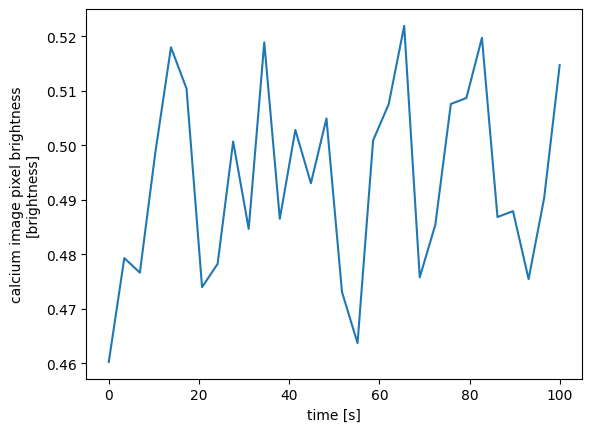

In [ ]:
da.mean(dim=['x', 'y']).plot();

There are many, many more features that XArray provides to add convenience to an analysis, but this should be enough to get us started. 

## Creating HDF5-based NetCDF4 Files with XArray

Once data is organized in an XArray structure, it can easily be saved to disk using scientific file formats such as NetCDF4, which is built on top of the HDF5 storage system. These formats are widely used in scientific computing because they support structured metadata, multidimensional datasets, and efficient storage of large arrays.

Saving data in these formats allows large datasets to be stored and accessed efficiently without requiring them to be fully loaded into memory. It also makes the data portable and accessible to tools outside of Python.

### Exercises

**Exercise**: Use `da.to_netcdf()`, using the `engine='netcdf4'` option, to create an HDF5-compatible file called `example.nc`.

In [ ]:
time = xr.DataArray(
    data = np.linspace(0, 100, 30),
    name = 'time',
    dims=['time'],
    attrs = {
        'units': 's',
        'description': 'time samples for each image frame'
    }
)

da = xr.DataArray(
    data=np.random.random(size=(10, 20, 30)),
    name='image',
    dims=['x', 'y', 'time'],
    coords = {
        'time': time,
    },
    attrs = {
        'units': 'brightness',
        'description': 'A generated random image stack',
        'long_name': 'calcium image pixel brightness',
    }
)
da

<xarray.DataArray 'image' (x: 10, y: 20, time: 30)> Size: 48kB
array([[[7.09283145e-01, 1.79002486e-01, 8.37909788e-01, ...,
 8.58189954e-01, 8.67664378e-01, 9.09663680e-01],
 [7.66024812e-01, 8.94774593e-01, 1.38657998e-01, ...,
 5.46136057e-01, 5.89969933e-01, 3.79270455e-01],
 [7.86070065e-01, 4.91618879e-01, 3.41728012e-01, ...,
 2.05409853e-01, 8.12357625e-01, 8.27954439e-01],
 ...,
 [3.61545859e-01, 8.13468563e-01, 9.05255037e-01, ...,
 1.07783055e-01, 9.63904981e-01, 1.98460550e-01],
 [1.58730461e-01, 4.68230170e-02, 5.13061777e-02, ...,
 8.81127529e-01, 8.57370835e-01, 1.94116052e-01],
 [5.40949159e-01, 1.74281856e-01, 5.58538309e-01, ...,
 8.18321435e-02, 7.72695454e-01, 2.95522931e-01]],

 [[2.63559287e-01, 9.35651946e-01, 6.59197576e-01, ...,
 5.73722017e-01, 9.77389810e-01, 7.39689298e-01],
 [6.05979193e-02, 4.26541327e-02, 2.58010361e-01, ...,
 8.19278690e-01, 8.65323731e-02, 2.49205231e-01],
 [2.60640028e-01, 5.37504868e-01, 4.13786575e-01, ...,
 8.83020856e-01, 6.21839330e-01, 6.34446325e-01],
...
 6.19590544e-01, 7.37009739e-01, 1.96289855e-01],
 [2.51302596e-01, 1.51421560e-01, 1.39316880e-01, ...,
 2.58255539e-02, 7.42068143e-01, 8.50447978e-01],
 [5.72703206e-01, 1.75382521e-01, 3.66152437e-01, ...,
 7.98444548e-01, 1.33694216e-01, 8.47039832e-01]],

 [[7.78419194e-01, 5.43900727e-01, 1.11485008e-01, ...,
 4.41826922e-01, 2.92492717e-02, 2.28756481e-01],
 [1.79974670e-01, 2.52460175e-02, 9.39361473e-01, ...,
 6.63427516e-01, 2.57709377e-01, 8.30607571e-01],
 [3.08162622e-01, 6.51628184e-02, 1.89788923e-01, ...,
 2.57369348e-01, 2.85842571e-01, 5.68417580e-01],
 ...,
 [3.64565811e-01, 7.55050473e-01, 6.25612551e-01, ...,
 1.96975224e-01, 5.69481457e-02, 9.80154538e-01],
 [8.16042448e-01, 7.76691128e-01, 5.08057218e-01, ...,
 4.28412177e-01, 2.23978219e-01, 1.96594705e-01],
 [4.18251436e-01, 2.62832696e-01, 4.38014311e-02, ...,
 3.99561652e-01, 4.24050772e-01, 3.27248178e-01]]],
 shape=(10, 20, 30))
Coordinates:
 * time (time) float64 240B 0.0 3.448 6.897 10.34 ... 93.1 96.55 100.0
Dimensions without coordinates: x, y
Attributes:
 units: brightness
 description: A generated random image stack
 long_name: calcium image pixel brightness xarray.DataArray 'image' x : 10 y : 20 time : 30 0.7093 0.179 0.8379 0.5 0.6536 ... 0.6157 0.445 0.3996 0.4241 0.3272 array([[[7.09283145e-01, 1.79002486e-01, 8.37909788e-01, ...,
 8.58189954e-01, 8.67664378e-01, 9.09663680e-01],
 [7.66024812e-01, 8.94774593e-01, 1.38657998e-01, ...,
 5.46136057e-01, 5.89969933e-01, 3.79270455e-01],
 [7.86070065e-01, 4.91618879e-01, 3.41728012e-01, ...,
 2.05409853e-01, 8.12357625e-01, 8.27954439e-01],
 ...,
 [3.61545859e-01, 8.13468563e-01, 9.05255037e-01, ...,
 1.07783055e-01, 9.63904981e-01, 1.98460550e-01],
 [1.58730461e-01, 4.68230170e-02, 5.13061777e-02, ...,
 8.81127529e-01, 8.57370835e-01, 1.94116052e-01],
 [5.40949159e-01, 1.74281856e-01, 5.58538309e-01, ...,
 8.18321435e-02, 7.72695454e-01, 2.95522931e-01]],

 [[2.63559287e-01, 9.35651946e-01, 6.59197576e-01, ...,
 5.73722017e-01, 9.77389810e-01, 7.39689298e-01],
 [6.05979193e-02, 4.26541327e-02, 2.58010361e-01, ...,
 8.19278690e-01, 8.65323731e-02, 2.49205231e-01],
 [2.60640028e-01, 5.37504868e-01, 4.13786575e-01, ...,
 8.83020856e-01, 6.21839330e-01, 6.34446325e-01],
...
 6.19590544e-01, 7.37009739e-01, 1.96289855e-01],
 [2.51302596e-01, 1.51421560e-01, 1.39316880e-01, ...,
 2.58255539e-02, 7.42068143e-01, 8.50447978e-01],
 [5.72703206e-01, 1.75382521e-01, 3.66152437e-01, ...,
 7.98444548e-01, 1.33694216e-01, 8.47039832e-01]],

 [[7.78419194e-01, 5.43900727e-01, 1.11485008e-01, ...,
 4.41826922e-01, 2.92492717e-02, 2.28756481e-01],
 [1.79974670e-01, 2.52460175e-02, 9.39361473e-01, ...,
 6.63427516e-01, 2.57709377e-01, 8.30607571e-01],
 [3.08162622e-01, 6.51628184e-02, 1.89788923e-01, ...,
 2.57369348e-01, 2.85842571e-01, 5.68417580e-01],
 ...,
 [3.64565811e-01, 7.55050473e-01, 6.25612551e-01, ...,
 1.96975224e-01, 5.69481457e-02, 9.80154538e-01],
 [8.16042448e-01, 7.76691128e-01, 5.08

In [ ]:
da.to_netcdf('example.nc', engine='netcdf4')

**Exercise**: Open the `example.nc` file in the HDF5 Viewer at https://myhdf5.hdfgroup.org/ to verify it is a valid HDF5 file, and use it to do the following tasks:
  1. View the `time` variable as a line plot.
  2. View the `time` values themselves in a matrix.
  3. View the Image data as a heatmap.
  4. Find the "description" attribute for the `image` variable (hint: check the `inspect` tab) 

#### Changing the `encoding` for a Variable to Save Space using Compression: `zlib` and `complevel`

Large scientific datasets often contain patterns that can be compressed effectively. NetCDF and HDF5 support built-in compression options, which can significantly reduce file size without altering the meaning of the data.

Compression settings such as `zlib` and `complevel` allow the file format to store the data more efficiently on disk. In some cases—particularly for structured or low-entropy data—the resulting file can be much smaller while remaining fully compatible with standard tools.  Other compression libraries are also supported, but here we'll just focus on the big picture: when and where compression helps (all options found [here](https://unidata.github.io/netcdf4-python/#netCDF4.Dataset.createVariable), for the interested)

The exercises in this section explore how compression affects file size for different types of data.

**Example**: Save the `da` DataArray below with two different encodings: one **without** zlib compression, and one **with** zlib compression.  How big of a file size reduction is there?

In [ ]:
da = xr.DataArray(np.random.random(1_000_000), name='data')

In [ ]:
da.to_netcdf('data1.nc', engine='netcdf4')
utils.print_file_size('data1.nc', 'No Compression ')

da.to_netcdf('data2.nc', engine='netcdf4', encoding={'data': {'zlib': True, 'complevel': 4}})
utils.print_file_size('data2.nc', 'Yes Compression', )

No Compression : 8.01 MB
Yes Compression: 6.75 MB


**Exercise**:  Save the `da` DataArray below with two different encodings: one **without** zlib compression, and one **with** zlib compression.  How big of a file size reduction is there?

In [ ]:
da = xr.DataArray(np.linspace(0, 10, 1_000_000), name='data')

In [ ]:
da.to_netcdf('data1.nc', engine='netcdf4')
utils.print_file_size('data1.nc', 'No Compression ')

da.to_netcdf('data2.nc', engine='netcdf4', encoding={'data': {'zlib': True, 'complevel': 4}})
utils.print_file_size('data2.nc', 'Yes Compression', )

No Compression : 8.01 MB
Yes Compression: 321.15 KB


**Exercise**: Save the `da` DataArray below with two different encodings: one **without** zlib compression, and one **with** zlib compression.  How big of a file size reduction is there?

In [ ]:
da = xr.DataArray(np.arange(1_000_000), name='data')

In [ ]:
da.to_netcdf('data1.nc', engine='netcdf4')
utils.print_file_size('data1.nc', 'No Compression ')

da.to_netcdf('data2.nc', engine='netcdf4', encoding={'data': {'zlib': True, 'complevel': 4}})
utils.print_file_size('data2.nc', 'Yes Compression', )

No Compression : 8.01 MB
Yes Compression: 27.65 KB


**Exercise**: Save the `da` DataArray below with two different encodings: one **without** zlib compression, and one **with** zlib compression.  How big of a file size reduction is there?

In [ ]:
da = xr.DataArray(np.zeros(1_000_000), name='data')

In [ ]:
da.to_netcdf('data1.nc', engine='netcdf4')
utils.print_file_size('data1.nc', 'No Compression ')

da.to_netcdf('data2.nc', engine='netcdf4', encoding={'data': {'zlib': True, 'complevel': 4}})
utils.print_file_size('data2.nc', 'Yes Compression', )

No Compression : 8.01 MB
Yes Compression: 16.03 KB


## Demos: Creating a Dataset from DataArrays

You already know how to create an `xr.DataArray`. A `Dataset` combines several named DataArrays into one object. **Dimensions** describe the axes of each variable; **coordinates** provide labels for positions along those axes. Variables can share dimensions and coordinates without having the same shape.

Let's build a miniature behavioral experiment before examining the real recording.

**Example:** We measured reaction time and stimulus contrast over four trials. Create two DataArrays using the **same** `trial` coordinate.

In [ ]:
trials = [10, 11, 12, 13]

reaction_time = xr.DataArray(
    [0.42, 0.35, 0.51, 0.39],
    dims=['trial'],
    coords={'trial': trials},
    name='reaction_time',
)

contrast_left = xr.DataArray(
    [0.0, 0.5, 1.0, 0.5],
    dims=['trial'],
    coords={'trial': trials},
    name='contrast_left',
)

reaction_time

<xarray.DataArray 'reaction_time' (trial: 4)> Size: 32B
array([0.42, 0.35, 0.51, 0.39])
Coordinates:
  * trial    (trial) int64 32B 10 11 12 13

**Example:** Combine the DataArrays into a Dataset. Dictionary keys become the variable names. Notice that `trial` appears **once** as a shared coordinate, while both measurements are separate data variables.

In [ ]:
experiment = xr.Dataset({
    'reaction_time': reaction_time,
    'contrast_left': contrast_left,
})
experiment

<xarray.Dataset> Size: 96B
Dimensions:        (trial: 4)
Coordinates:
  * trial          (trial) int64 32B 10 11 12 13
Data variables:
    reaction_time  (trial) float64 32B 0.42 0.35 0.51 0.39
    contrast_left  (trial) float64 32B 0.0 0.5 1.0 0.5

**Example:** Add a `response_type` DataArray with the values `['left', 'right', 'right', 'left']`, indexed by the same trials. Then add it to the Dataset and inspect `experiment`.

*Hint:* A Dataset can be extended just like a dictionary: `experiment['response_type'] = ...`.

In [ ]:
response_type = xr.DataArray(
    ['left', 'right', 'right', 'left'],
    dims=['trial'],
    coords={'trial': trials},
)
experiment['response_type'] = response_type
experiment

<xarray.Dataset> Size: 176B
Dimensions:        (trial: 4)
Coordinates:
  * trial          (trial) int64 32B 10 11 12 13
Data variables:
    reaction_time  (trial) float64 32B 0.42 0.35 0.51 0.39
    contrast_left  (trial) float64 32B 0.0 0.5 1.0 0.5
    response_type  (trial) <U5 80B 'left' 'right' 'right' 'left'

### Different dimensions, same Dataset

Suppose we also measured pupil size at three time points during each trial. This variable has **two dimensions**, `trial` and `time`. The other variables only have `trial`. They can all live in the same Dataset because the shared `trial` axis refers to the same trials.

**Example:** Create the pupil-size DataArray and add it to `experiment`. Examine the Dataset's dimensions, coordinates, and data variables.

In [ ]:
pupil_size = xr.DataArray(
    [[2.1, 2.3, 2.2],
     [2.0, 2.2, 2.4],
     [2.3, 2.4, 2.5],
     [2.2, 2.1, 2.3]],
    dims=['trial', 'time'],
    coords={'trial': trials, 'time': [0.0, 0.5, 1.0]},
)
experiment['pupil_size'] = pupil_size
experiment

**Exercise:** Select trial `12` from the *whole Dataset* using `.sel(trial=12)`. Which measurements are returned? Then select the pupil measurements at time `0.5` for **all trials**.

Notice that coordinate labels (such as trial `12`) are not necessarily the same as positional indices.

In [ ]:
experiment.sel(trial=12)

**Key idea:** Matching dimension names tell Xarray which axes are related; coordinate labels tell it *which observations correspond*. If labels differ, Xarray may reorder, align, or introduce missing values, depending on the operation. Always inspect the coordinates when combining data.

Now look for these same relationships in the real Steinmetz Dataset below: some variables describe trials, some describe cells, and `spike_count` spans cells, trials, and time.

## Analysis Requires Memory: Monitoring Memory Usage for Chained Pipelines

Even when data is stored efficiently on disk, analysis pipelines can still consume large amounts of memory. This is particularly true when multiple operations are chained together, since intermediate results may temporarily allocate large arrays.

In this section, we monitor the memory usage of different analysis pipelines while performing simple computations on an imaging dataset. By observing how memory usage changes over time, it becomes easier to see how different data-loading strategies affect resource consumption.

These experiments illustrate an important principle: the way data is loaded and processed can matter just as much as the analysis itself.

### Exercises

In [ ]:
utils.generate_calcium_data_file('calcium_data.nc')

**Example**: Compute Two Different Mean Projections: one over all pixels, and one over a selection of the frame (a "Region of Interest")

1. Update the functions and run the cell

In [ ]:
def mean_all_data():
    return (
        xr.load_dataarray('calcium_data.nc')
        .mean(dim='time')
    )

def mean_roi_data():
    return (
        xr.load_dataarray('calcium_data.nc')
        .sel(x=slice(0, 100), y=slice(0, 100))
        .mean(dim='time')
    )

2. Check that the functions work: plot each of the generated images.

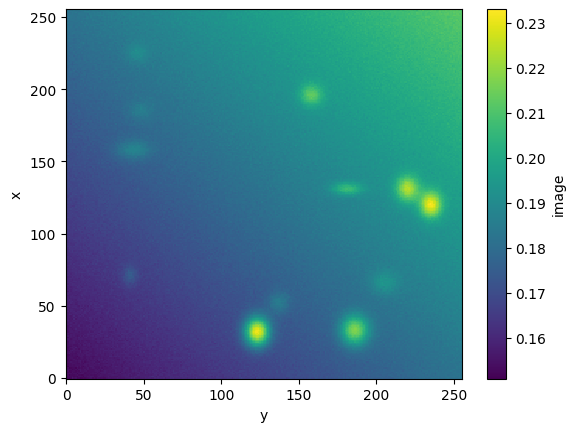

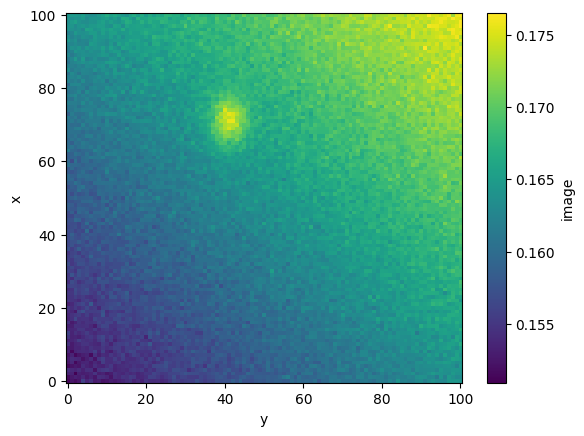

In [ ]:
mean_all_data().plot()
plt.figure()
mean_roi_data().plot()

3. How much memory do each of the two functions use? Plot a comparison between the two functions.

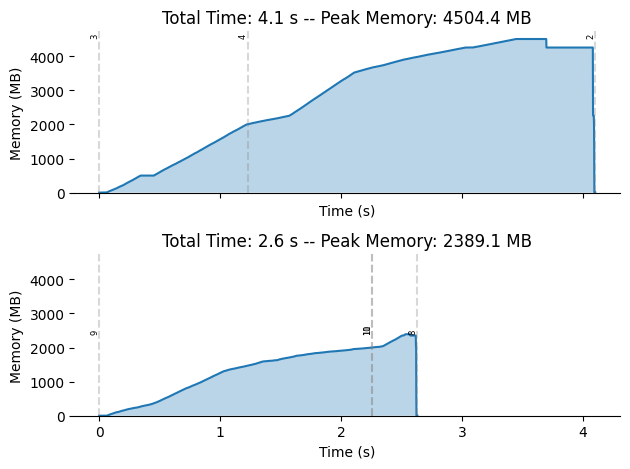

In [ ]:
utils.analyze_memory(
    mean_all_data,
    mean_roi_data,
)


**Exercise**: Modify the second of the mean-projection functions below to use `xr.open_dataarray()`, which opens the file but doesn't load the data until it is requested.

1. Update the functions and run the cell

In [ ]:
def mean_roi_data():
    return (
        xr.load_dataarray('calcium_data.nc')
        .sel(x=slice(0, 100), y=slice(0, 100))
        .mean(dim='time')
    )

def mean_roi_data2():
    return (
        xr.load_dataarray('calcium_data.nc')
        .sel(x=slice(0, 100), y=slice(0, 100))
        .mean(dim='time')
    )

In [ ]:
def mean_roi_data():
    return (
        xr.load_dataarray('calcium_data.nc')
        .sel(x=slice(0, 100), y=slice(0, 100))
        .mean(dim='time')
    )

def mean_roi_data2():
    return (
        xr.open_dataarray('calcium_data.nc')
        .sel(x=slice(0, 100), y=slice(0, 100))
        .mean(dim='time')
    )

2. Check that the functions still work as before: plot each of the generated images and compare them; despite having different code, they should show the same result.

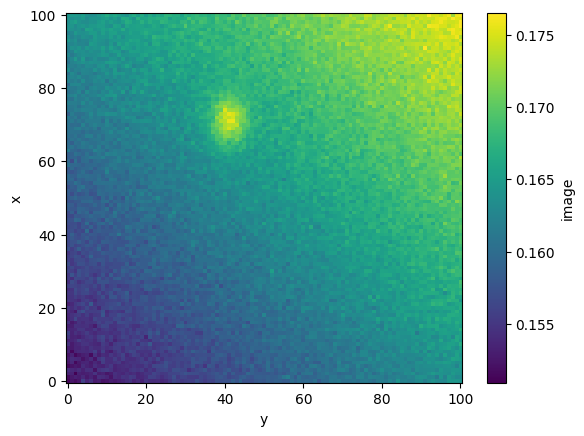

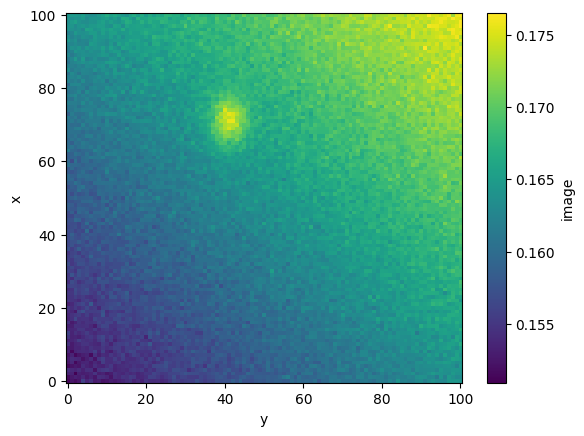

In [ ]:
mean_roi_data().plot()
plt.figure()
mean_roi_data2().plot()

3. How much memory do each of the two functions use? Plot a comparison between the two functions. Is there a significant diffrence between the two?

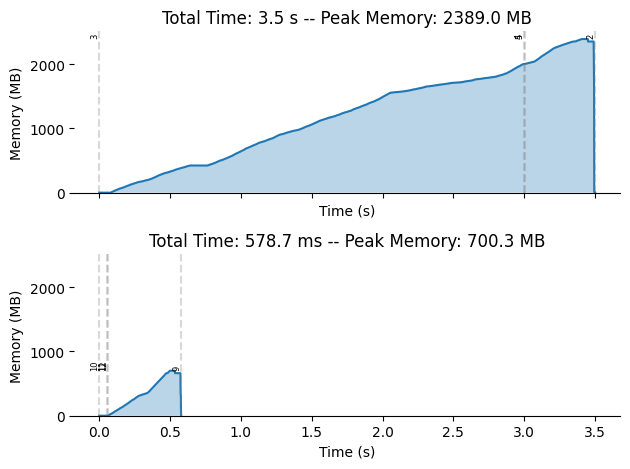

In [ ]:
utils.analyze_memory(
    mean_roi_data,
    mean_roi_data2,
)


**Exercise**: Modify the third of the mean-projection functions below to use `xr.open_dataarray(chunks='auto')`, which opens the file, but doesn't load the data until the full computation is requested (i.e. add `.compute()`) to the end of the pipeline.

1. Update the functions and run the cell

In [ ]:
def mean_roi_data():
    return (
        xr.load_dataarray('calcium_data.nc')
        .sel(x=slice(0, 100), y=slice(0, 100))
        .mean(dim='time')
    )

def mean_roi_data2():
    return (
        xr.open_dataarray('calcium_data.nc')
        .sel(x=slice(0, 100), y=slice(0, 100))
        .mean(dim='time')
    )


def mean_roi_data3():
    return (
        xr.open_dataarray('calcium_data.nc')
        .sel(x=slice(0, 100), y=slice(0, 100))
        .mean(dim='time')
        .compute()
    )

In [ ]:
def mean_roi_data():
    return (
        xr.load_dataarray('calcium_data.nc')
        .sel(x=slice(0, 100), y=slice(0, 100))
        .mean(dim='time')
    )

def mean_roi_data2():
    return (
        xr.open_dataarray('calcium_data.nc')
        .sel(x=slice(0, 100), y=slice(0, 100))
        .mean(dim='time')
    )


def mean_roi_data3():
    return (
        xr.open_dataarray('calcium_data.nc', chunks='auto')
        .sel(x=slice(0, 100), y=slice(0, 100))
        .mean(dim='time')
        .compute()
    )

2. Check that the the functions all still work as before: plot each of the generated images and compare them; despite having different code, they should show the same result.

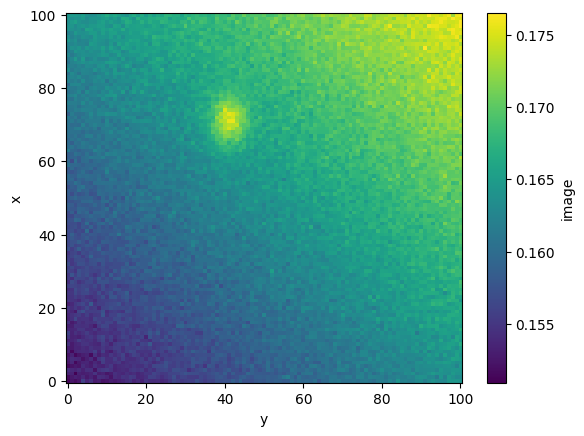

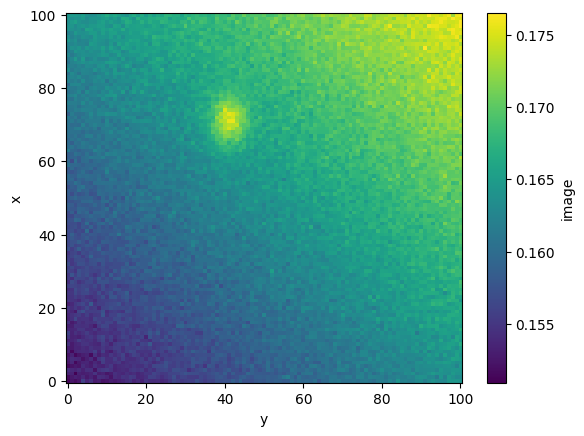

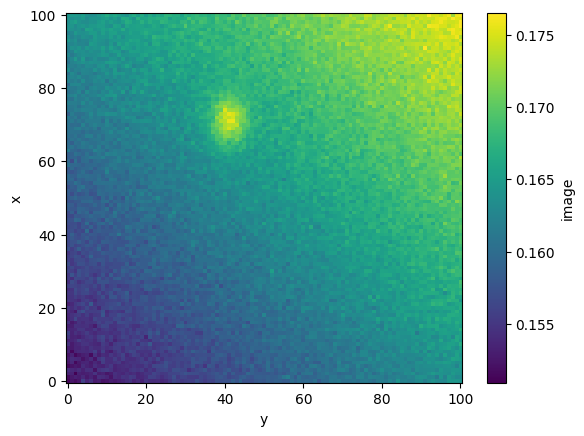

In [ ]:
mean_roi_data().plot()
plt.figure()
mean_roi_data2().plot()
plt.figure()
mean_roi_data3().plot()

3. How much memory do each of the three functions use? Plot a comparison between the three functions. Is there a significant diffrence between the three?

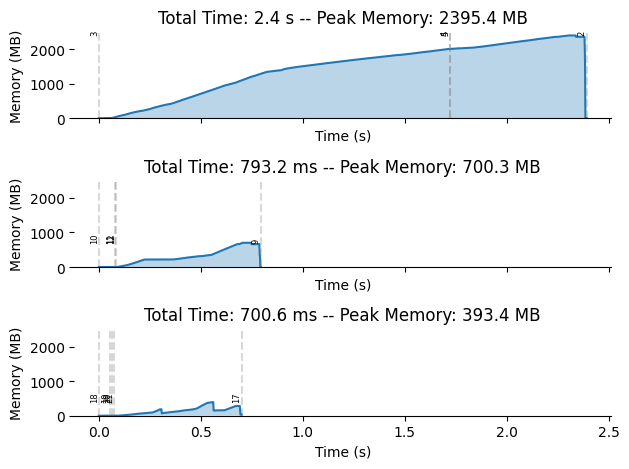

In [ ]:
utils.analyze_memory(
    mean_roi_data,
    mean_roi_data2,
    mean_roi_data3,
)


## Monitoring Dask's Workflow

When Dask executes chunked computations, it constructs a task graph describing how different pieces of the computation depend on each other. A distributed Dask client provides a dashboard that visualizes this process in real time, showing how tasks are scheduled, executed, and completed across workers.

The dashboard allows users to observe how work is distributed, how memory usage changes over time, and how intermediate results flow through the computation graph. This visibility is especially valuable when analyzing large datasets or debugging performance issues.

**Exercise**: Uncomment and run the following code to shift computations out of the process, into a "Distributed Dask" client (note: this will make it so that the `utils.analyze_memory()` function can no longer access the dask-processed data; monitoring will have to be done from the dask workers).  Open the resulting web page and browse through the sections.

In [ ]:
#import dask.distributed
#client = dask.distributed.Client()
#client

**Exercise**: Run the following code over and over, while simultaneously viewing the client monitoring dashboard, looking at different sections of the dashboard, and answer the following questions:
  1. How many workers are processing the data?
  2. Do the workers just break up the work evenly from the beginning, or is there more complex cooperation happening between them?
  3. How many different tasks was the workflow broken down into?
  4. Is memory released between tasks?
  5. Is there a simple relationship between each each task, or is there a more complex compute graph being run?

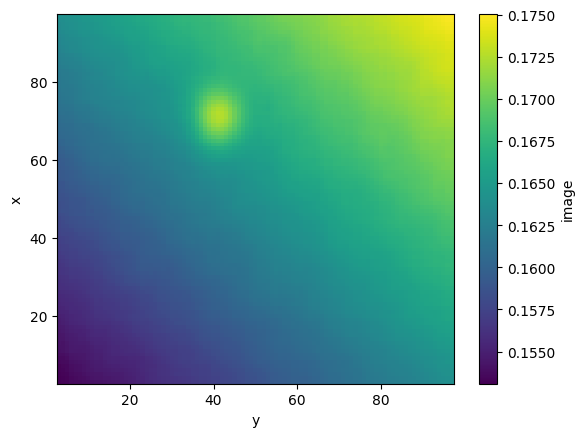

In [ ]:
(xr.open_dataarray('calcium_data.nc', chunks='auto')
    .sel(x=slice(0, 100), y=slice(0, 100))
    .mean(dim='time')
    .rolling(x=7, center=True).mean()
    .dropna('x')
    .rolling(y=7, center=True).mean()
    .dropna('y')
    .compute()
    .plot()
)